## 0. Preparar entorno

In [2]:
# Paso 0. Importar librerias

# Datos ----------------------------------------------------------------
import pandas as pd
import numpy as np
# Graficos -------------------------------------------------------------
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning -----------------------------------------------------
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer, 
    OneHotEncoder, 
    StandardScaler)
from sklearn.decomposition import PCA
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    confusion_matrix, 
    ConfusionMatrixDisplay, 
    roc_auc_score, 
    classification_report,
    precision_recall_curve,
    roc_curve,
    auc as sk_auc,
    f1_score)
from sklearn.preprocessing import PowerTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn import tree
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (accuracy_score,
                             classification_report,
                             f1_score,
                             recall_score,
                             confusion_matrix,
                             classification_report)
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import GridSearchCV
import xgboost as xgb

import plotly.express as px
import requests
from io import StringIO

# Modelo ---------------------------------------------------------------
from joblib import dump
import pickle
import os

## 1. Cargar datos

Objetivo: Obtener los datos de la fuente y una primera visión de las propiedades, más una presentación.

In [3]:
df_raw = pd.read_csv("../data/raw/bank-additional-full.csv", sep=';')
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

## Dictionary:

|# | Feature | Type        | Description   |
|--|---------|-------------|---------------|
|1 | age     | numeric      | age of person |
|2 | job     | categorical  | type of job:  <br>'admin.'<br>'blue-collar'<br>'entrepreneur'<br>'housemaid'<br>'management'<br>'retired'<br>'self-employed'<br>'services'<br>'student'<br>'technician'<br>'unemployed'<br>'unknown'|
|3 | marital | categorical |marital status: <br>'divorced'<br>'married'<br>'single'<br>'unknown'<br> note: 'divorced' means divorced or widowed|
|4 | education | categorical | status education: <br>'basic.4y'<br>'basic.6y'<br>'basic.9y'<br>'high.school'<br>'illiterate'<br>'professional.course'<br>'university.degree'<br>'unknown'|
|5 | default | categorical | has credit in default? <br>'no'<br>'yes'<br>'unknown'|
|6 | housing | categorical | has housing loan?: <br>'no'<br>'yes'<br>'unknown'|
|7 | loan | categorical | has personal loan?: <br>'no'<br>'yes'<br>'unknown'|

### Related with the last contact of the current campaign:
|# | Feature | Type        | Description   |
|--|---------|-------------|---------------|
|8 | contact | categorical | contact communication type: <br>'cellular'<br>'telephone'|
|9 | month | categorical | last contact month of year: <br>'jan'<br>'feb'<br>'mar'<br> ...<br> 'nov'<br>'dec'|
|10| day_of_week | categorical | last contact day of the week: <br>'mon'<br>'tue'<br>'wed'<br>'thu'<br>'fri'|
|11| duration | numeric | last contact duration, in seconds. <br>Important note: this attribute highly affects the output target (e.g., if duration=0 then y='no'). Yet, the duration is not known before a call is performed. Also, after the end of the call y is obviously known. Thus, this input should only be included for benchmark purposes and should be discarded if the intention is to have a realistic predictive model.|

### Other attributes:

|# | Feature | Type        | Description   |
|--|---------|-------------|---------------|
|12| campaign | numeric | number of contacts performed during this campaign and for this client (numeric, includes last contact)|
|13| pdays | numeric | number of days that passed by after the client was last contacted from a previous campaign (numeric; 999 means client was not previously contacted)|
|14| previous | numeric | number of contacts performed before this campaign and for this client|
|15| poutcome | categorical | outcome of the previous marketing campaign: <br>'failure'<br>'nonexistent'<br>'success'|

### Social and economic context attributes

|# | Feature | Type        | Description   |
|--|---------|-------------|---------------|
|16| emp.var.rate | numeric | employment variation rate - quarterly indicator |
|17| cons.price.idx | numeric | consumer price index - monthly indicator |
|18| cons.conf.idx | numeric | consumer confidence index - monthly indicator |
|19| euribor3m | numeric | euribor 3 month rate - daily indicator |
|20| nr.employed | numeric | number of employees - quarterly indicator | 

### Output variable (desired target):
|# | Feature | Type        | Description   |
|--|---------|-------------|---------------|
|21| y | binary | has the client subscribed a term deposit?: <br>'yes'<br>'no'|

In [4]:
df_raw.sample(10, random_state=2025)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
4479,58,retired,married,basic.4y,unknown,no,no,telephone,may,tue,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.856,5191.0,yes
24230,51,entrepreneur,married,university.degree,no,yes,no,cellular,nov,mon,...,1,999,0,nonexistent,-0.1,93.200,-42.0,4.191,5195.8,no
8307,43,admin.,married,high.school,no,yes,no,telephone,jun,tue,...,2,999,0,nonexistent,1.4,94.465,-41.8,4.864,5228.1,no
4824,31,admin.,married,high.school,no,no,no,telephone,may,wed,...,2,999,0,nonexistent,1.1,93.994,-36.4,4.858,5191.0,no
12201,41,blue-collar,married,basic.6y,no,no,no,telephone,jul,wed,...,5,999,0,nonexistent,1.4,93.918,-42.7,4.956,5228.1,no
20123,36,housemaid,married,basic.6y,no,no,no,cellular,aug,mon,...,2,999,0,nonexistent,1.4,93.444,-36.1,4.965,5228.1,no
11995,44,admin.,married,university.degree,unknown,yes,yes,telephone,jun,thu,...,4,999,0,nonexistent,1.4,94.465,-41.8,4.955,5228.1,no
9514,45,admin.,married,university.degree,no,yes,no,telephone,jun,mon,...,5,999,0,nonexistent,1.4,94.465,-41.8,4.961,5228.1,no
20217,48,entrepreneur,married,university.degree,no,yes,no,cellular,aug,mon,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.965,5228.1,no
8739,22,services,single,high.school,no,no,no,telephone,jun,wed,...,1,999,0,nonexistent,1.4,94.465,-41.8,4.864,5228.1,no


## Consideraciones iniciales

- y: al estar desbalanceado es importante considerar técnicas de balanceo o métricas como ROC AUC, F1-score.
- Eliminar duration del modelado realista (pero usarlo como benchmark para comparación).
- Convertir unknown en nulos (NaN) o como categoría si tiene sentido semántico.
- Codificar variables categóricas con one-hot encoding (o label encoding para árboles).
- Evaluar correlaciones y multicolinealidad especialmente en variables económicas.
- Analizar la distribución de y para preparar modelos robustos ante el desbalance.

¿Qué representa duration?
Es la duración de la última llamada telefónica (en segundos) entre el agente del banco y el cliente.

¿Por qué NO debe usarse para predecir y en un modelo realista?
Porque se conoce solo después de que la llamada ya ocurrió. Por ejemplo:

- Si el cliente cuelga rápido (duración = 0–5 seg), es muy probable que no se suscriba → y = no
- Si el cliente habla más tiempo (ej: >300 seg), suele haber más chances de que termine aceptando la oferta → y = yes

Pero: Si estás entrenando un modelo para predecir antes de llamar si vale la pena contactar a ese cliente, no podés saber la duración de la llamada de antemano, porque aún no ha ocurrido.

¿Por qué puede usarse como benchmark?
Podés incluirla en un modelo solo con fines comparativos, es decir:

- Entrenar dos modelos:
    - Uno realista (sin duration)
    - Uno con duration (benchmark)
- Evaluar cuánto mejora el modelo incluyendo duration, sabiendo que ese modelo no sirve para producción, pero te ayuda a medir el techo de performance del dataset.

Ejemplo práctico:
Supongamos:

- Modelo A (sin duration) → AUC = 0.78
- Modelo B (con duration) → AUC = 0.92

Eso te dice: “Este problema es en parte fácil de resolver si ya sabés cómo fue la llamada, pero sin esa información, el modelo tiene un techo de performance del 78% de AUC”.

## EDA global

In [5]:
print("Describe numerics")
display(df_raw.describe(include='number').T)
print("Describe categoricals")
display(df_raw.describe(include='object').T)

Describe numerics


,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


Describe categoricals


,count,unique,top,freq
job,41188,12,admin.,10422
marital,41188,4,married,24928
education,41188,8,university.degree,12168
default,41188,3,no,32588
housing,41188,3,yes,21576
loan,41188,3,no,33950
contact,41188,2,cellular,26144
month,41188,10,may,13769
day_of_week,41188,5,thu,8623
poutcome,41188,3,nonexistent,35563


## Obervaciones variables numéricas

| Variable                                                      | Observación                                   | Interpretación                                                                                | Posibles estrategias                                                                                                                                    |
| ------------------------------------------------------------- | --------------------------------------------- | --------------------------------------------------------------------------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------- |
| `age`                                                         | Rango 17–98, media 40, p75=47                 | Distribución moderadamente sesgada a la derecha (clientes mayores)                            | 1. Crear bins (18–25, 26–35, … 65+) para entender patrones por etapa de vida<br>2. O dejarla continua si el modelo es no lineal (árboles)             |
| `duration`                                                    | media < std, máx=4918                         | Distribución muy dispersa. Casos extremos de duración que probablemente indican éxito         | ⚠️ Excluir del modelado predictivo (no conocido antes del contacto), usar solo para **benchmark**                                                       |
| `campaign`                                                    | máx=56, media=2.5, p75=3                      | Alta varianza y casos extremos (outliers)                                                     | 1. Winsorizar (cap a máx 10, por ejemplo)<br>2. Evaluar impacto de campañas insistentes en tasa de éxito                                              |
| `pdays`                                                       | media \~962, p25/p50/p75=999                  | Casi todos los valores son 999 (no contactado antes)                                          | 1. Reemplazar 999 por NaN y crear variable binaria `prev_contacted`<br>2. O mantenerlo como `categoría` (999 = no contactado)                         |
| `previous`                                                    | media=0.17, p75=0, máx=7                      | Más del 75% nunca tuvo contacto previo                                                        | Similar a `pdays`: usar como binaria o dejar como está si el modelo puede manejar ceros frecuentes                                                      |
| `emp.var.rate`                                                | std > mean, rango -3.4 a 1.4                  | Económicamente relevante. Negativo indica caída en empleo                                     | 1. Normalizar<br>2. Evaluar correlación con `y` para decisiones macro                                                                                 |
| `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` | Variables macroeconómicas con baja dispersión | Menor varianza → menor peso individual, pero pueden tener efecto conjunto (multicolinealidad) | 1. Estudiar correlación entre estas variables<br>2. PCA opcional si hay redundancia<br>3. Estandarizar si se usan modelos sensibles (regresión, SVM) |

## Observaciones variables categóricas

| Variable                          | Observación                                    | Interpretación                                                                | Posibles estrategias                                                                                                                       |
| --------------------------------- | ---------------------------------------------- | ----------------------------------------------------------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------ |
| `job`                             | 12 categorías, predominio de "admin."          | Segmentación laboral: importante para targeting                               | 1. Reagrupar en sectores si es necesario ("blue collar", "white collar", "student", "retired")<br>2. One-hot encoding                    |
| `marital`                         | "married" es 60%                               | Estado civil puede influir en riesgo o preferencia de ahorro                  | No reagrupar, usar tal como está. Posible correlación con edad                                                                             |
| `education`                       | "university.degree" y "high.school" dominan    | Nivel educativo alto puede correlacionarse con propensión al ahorro/inversión | Posible codificación ordinal (illiterate < basic < high school < university) o one-hot                                                     |
| `default`, `housing`, `loan`      | Alta proporción de "no" y varios "unknown"     | Potencial omisión o confidencialidad. "unknown" no es aleatorio               | 1. Analizar si "unknown" se comporta distinto en función de `y`. Si no → imputar / eliminar<br>2. Si sí → tratarlo como categoría válida |
| `contact`, `month`, `day_of_week` | "cellular" y "may" dominan, "thu" es más común | Podría haber **sesgo de campaña** (ej: mayoría de contactos en mayo y jueves) | 1. Revisar impacto de "month" en éxito<br>2. Evitar que el modelo confunda patrón temporal con causalidad                                |
| `poutcome`                        | "nonexistent" en 86%                           | Muy desbalanceada, pero "success" tiene fuerte peso predictivo                | Mantener como está. One-hot encoding recomendado                                                                                           |



## Estrategia General Recomendada

**EDA por segmentos clave:**
- Suscripción (y) por job, education, month, poutcome
- Distribuciones de age, campaign, duration

**Preprocesamiento**
- One-hot encoding de categóricas (o ordinal si aplica)
- Eliminar duration en modelado realista
- Crear variables binarias nuevas (ej: was_contacted_before, has_previous_success)
- Tratar "unknown" como categoría o imputar si tiene suficiente peso

**Modelado**
- Entrenar sin y con balanceo (class_weight='balanced', SMOTE)
- Comparar modelos con ROC AUC y F1

**Explicabilidad**
- Analizar feature importances
- Relacionar findings con decisiones de marketing: ¿Qué perfiles de clientes y qué contexto económico son más sensibles a las campañas?

## Análisis univariado (var-num)

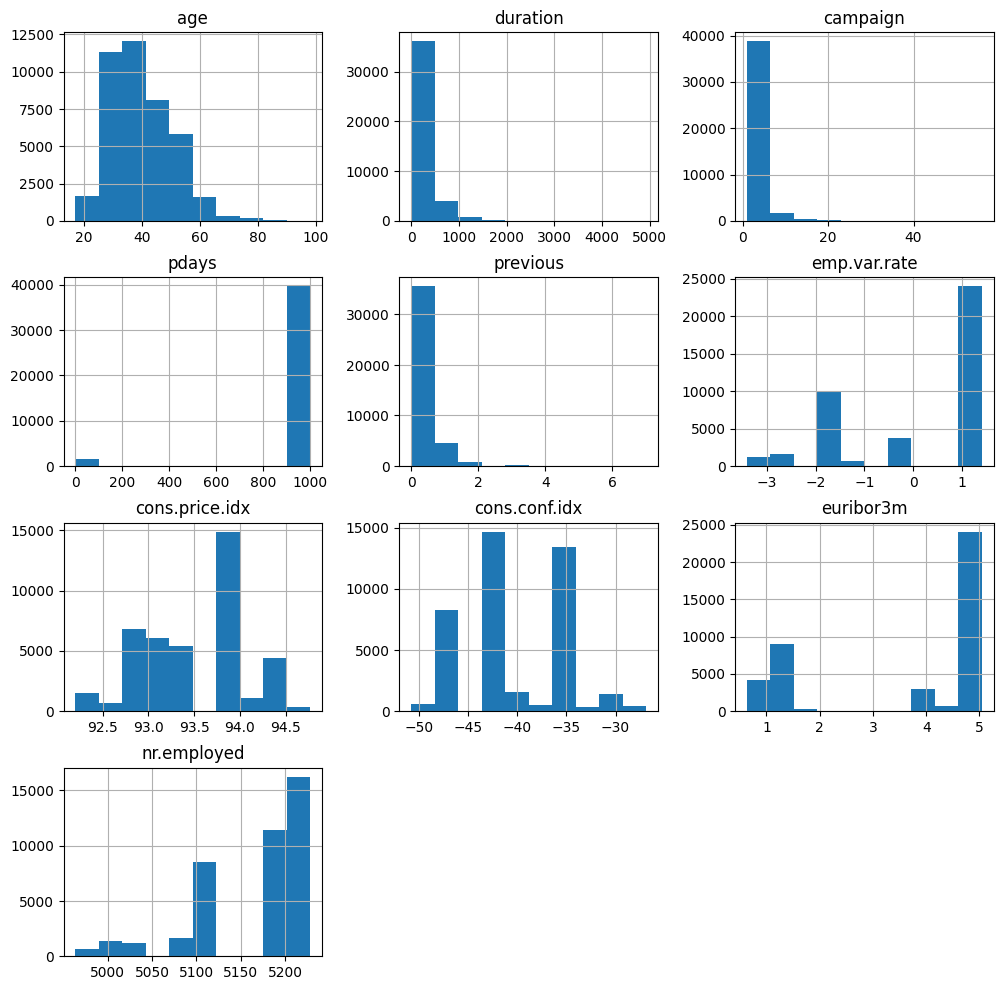

In [6]:
# Análisis univariado (variables numéricas)
df_raw.hist(figsize=(12,12))
plt.show()

## Análisis

| Variable           | Observación visual                                                                          | Conclusiones                                                                                                                                              |
| ------------------ | ------------------------------------------------------------------------------------------- | --------------------------------------------------------------------------------------------------------------------------------------------------------- |
| **age**            | Distribución sesgada a la derecha, concentrada entre 20 y 60 años.                          | Distribución natural, sin outliers extremos. Se puede dejar continua o aplicar *binning* para análisis por etapa de vida.                               |
| **duration**       | Claramente sesgada. Mayoría de llamadas cortas (muchas en 0–200 seg), con valores extremos. | Confirmación de que debe excluirse del modelo realista. Sirve solo como benchmark. Outliers muy influyentes.                                           |
| **campaign**       | Sesgo fuerte hacia el 1–3. Hay outliers hasta 50+ contactos.                                | Hay saturación de llamadas en algunos clientes. Considerar **winsorización** o binarizar >5 contactos.                                                 |
| **pdays**          | Distribución completamente dominada por valor 999.                                          | Este valor debe tratarse aparte. Crear variable binaria "fue\_contactado\_previamente". El valor como tal tiene poca utilidad en su forma original.    |
| **previous**       | Mayoría de valores en 0. Muy pocos tienen interacciones previas.                            | Altamente desbalanceada. Puede transformarse en variable binaria: "tuvo\_contactos\_previos".                                                          |
| **emp.var.rate**   | Picos en -1.8 y 1.1. Distribución multimodal.                                               | Esta variable refleja momentos económicos concretos. Puede tener valor predictivo si se combina con fecha o campaña. Mantener sin modificar por ahora. |
| **cons.price.idx** | Discreta, con valores agrupados en pocos puntos.                                            | Parece capturada en momentos específicos. Poca variación → poca capacidad explicativa individual, pero útil combinada. No requiere transformación.     |
| **cons.conf.idx**  | Valores agrupados, picos notorios en -41, -36, -45.                                         | Similar a `cons.price.idx`. Mantener como está. Revisar correlación con suscripción (`y`).                                                                |
| **euribor3m**      | Bimodal: mayoría en valores altos (\~5) y otra en valores bajos (\~1).                      | Indica condiciones monetarias. Puede ser fuerte predictor indirecto. Mantener tal cual. Modelos no lineales pueden capturar bien esta forma.           |
| **nr.employed**    | Concentración en valores alrededor de 5150–5228.                                            | Similar a las macroeconómicas anteriores. Alta correlación esperada con `emp.var.rate`. Revisar colinealidad.                                          |


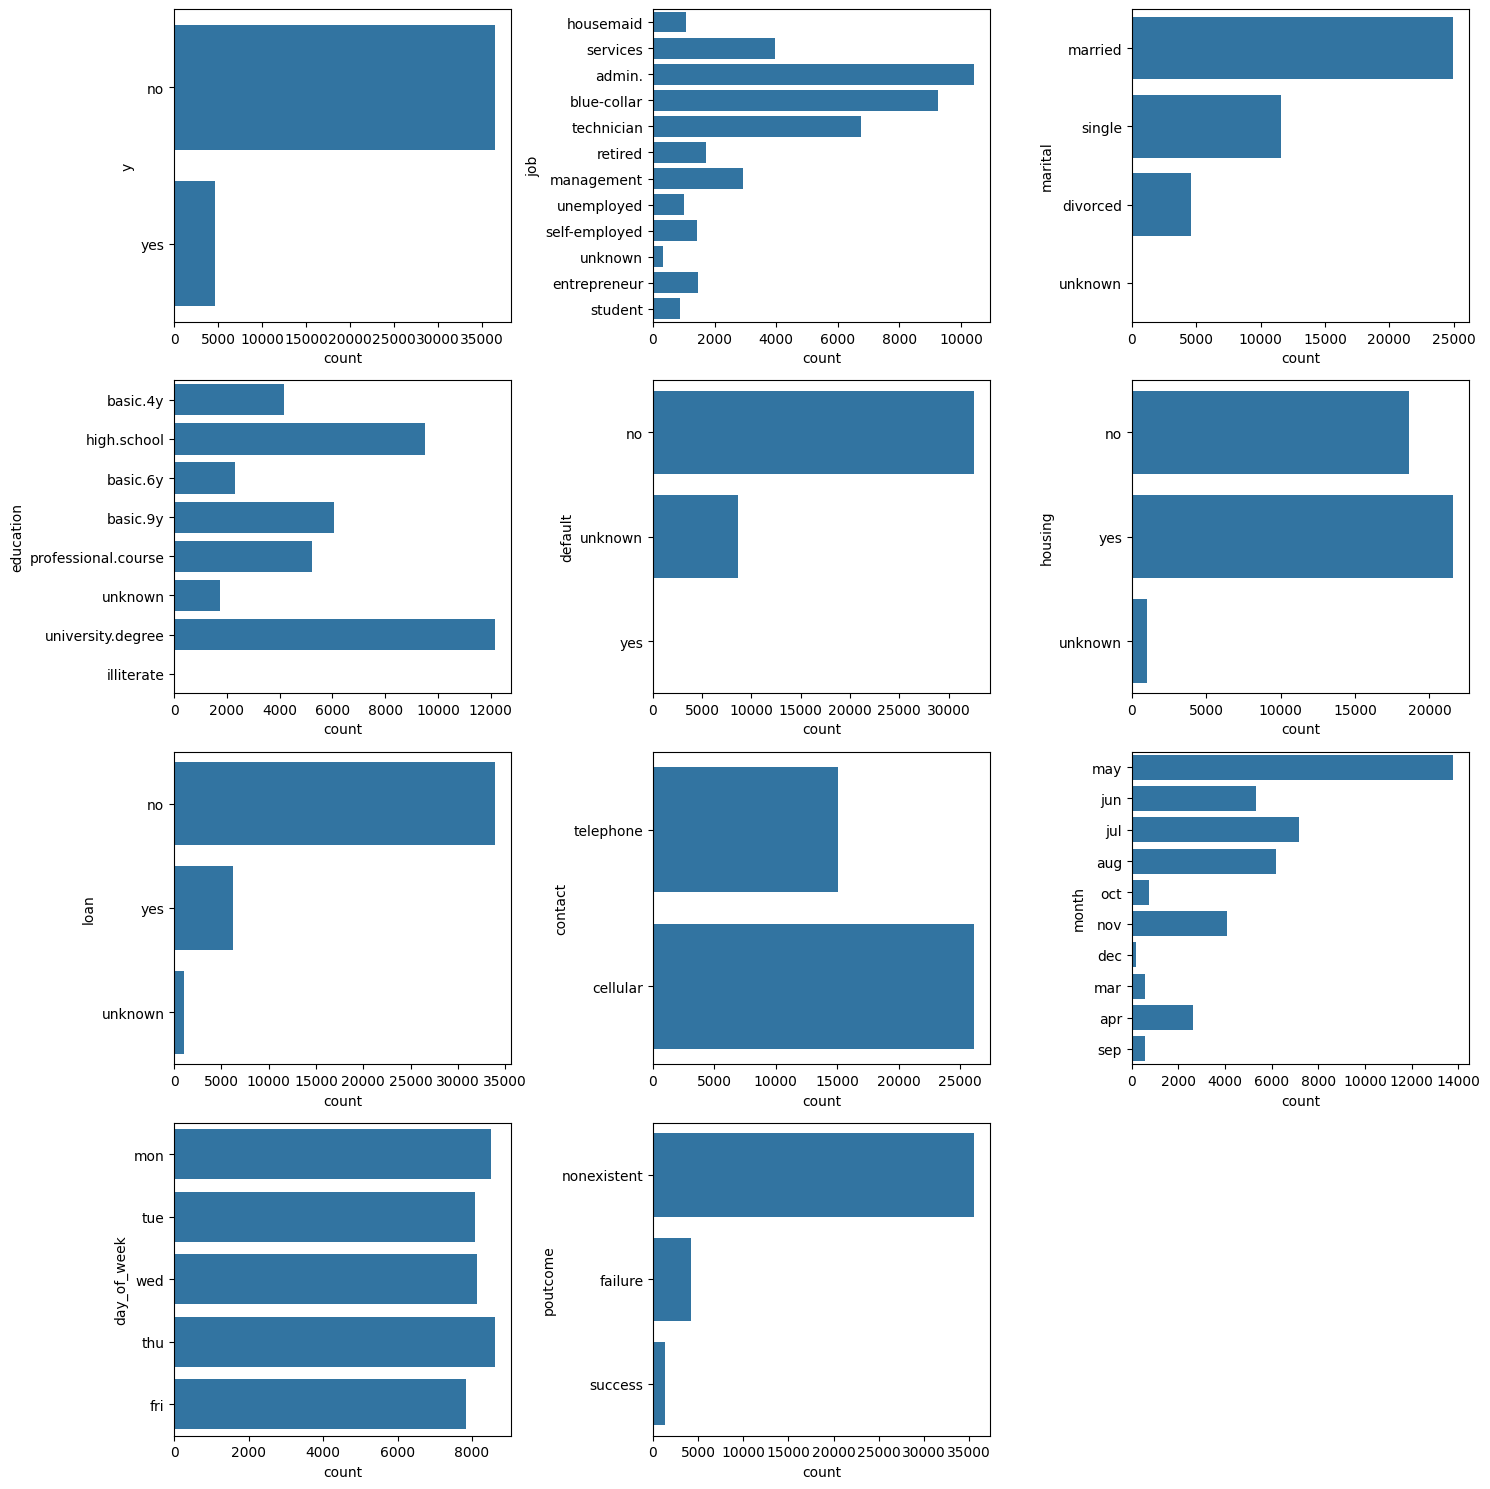

In [7]:
# Analisis univariado (variables categóricas)
fig, ax = plt.subplots(4, 3, figsize=(15, 15))
sns.countplot(data= df_raw, y= 'y', ax= ax[0, 0])
sns.countplot(data= df_raw, y= 'job', ax= ax[0, 1])
sns.countplot(data= df_raw, y= 'marital', ax= ax[0, 2])
sns.countplot(data= df_raw, y= 'education', ax= ax[1, 0])
sns.countplot(data= df_raw, y= 'default', ax= ax[1, 1])
sns.countplot(data= df_raw, y= 'housing', ax= ax[1, 2])
sns.countplot(data= df_raw, y= 'loan', ax= ax[2, 0])
sns.countplot(data= df_raw, y= 'contact', ax= ax[2, 1])
sns.countplot(data= df_raw, y= 'month', ax= ax[2, 2])
sns.countplot(data= df_raw, y= 'day_of_week', ax= ax[3, 0])
sns.countplot(data= df_raw, y= 'poutcome', ax= ax[3, 1])

fig.delaxes(ax[3, 2])
plt.tight_layout()
plt.show()

## Análisis

| Variable          | Observaciones Visuales                                                                                                         | Conclusiones y Estrategias                                                                                                                                                                     |
| ----------------- | ------------------------------------------------------------------------------------------------------------------------------ | ---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| **y (target)**    | Fuerte desbalance: \~88% "no", \~12% "yes"                                                                                     | Confirmado. Evaluar con métricas como **ROC AUC** y **F1-score**. Balanceo con `class_weight`, SMOTE o similar será necesario.                                                              |
| **job**           | Predominan: *admin.*, *blue-collar*, *technician*<br>Categorías con muy pocos ejemplos: *housemaid*, *entrepreneur*, *student* | 1. Podés reagrupar en sectores: "asalariados", "independientes", "sin actividad".<br>2. Algunas clases tienen muy pocos ejemplos → riesgo de sobreajuste con one-hot encoding.               |
| **marital**       | Dominancia clara de "married", seguido por "single"                                                                            | Segmentación clásica. Puede correlacionarse con edad. Mantener. Considerar interacciones con `education` o `job`.                                                                              |
| **education**     | Mayoría tiene "university.degree", luego "high.school". Muchos "unknown"                                                       | 1. Puede codificarse ordinalmente si el modelo lo permite.<br>2. Investigar si los "unknown" se comportan distinto en función de `y`.                                                        |
| **default**       | Mayoría "no", gran cantidad de "unknown", pocos "yes"                                                                          | La clase "yes" es ínfima → puede no aportar valor. <br>Opción: binarizar (default/no) y agrupar "unknown" como clase separada o eliminar si no aporta valor predictivo.                  |
| **housing**       | Distribución relativamente equilibrada entre "yes" y "no", también hay "unknown"                                               | Potencialmente informativa. Tratar "unknown" como categoría separada y verificar correlación con `y`.                                                                                        |
| **loan**          | Predomina "no" (\~34k), "yes" y "unknown" con menos peso                                                                       | Similar estrategia a `housing`. Puede ser binaria. Revisar impacto individual y en combinación con `job` o `age`.                                                                              |
| **contact**       | Claramente domina "cellular" sobre "telephone"                                                                                 | Es informativa. Posible influencia de canal sobre tasa de éxito. Podés cruzarla con `y` para ver diferencias.                                                                                |
| **month**         | Claramente sesgada: pico muy alto en "may", luego caídas fuertes. Pocos casos en "dec", "mar", "apr"                           | Indica **sesgo de campaña**. Puede afectar el modelo si se entrena con datos de campañas más agresivas en ciertos meses. Evaluar `y` por mes. Considerar agrupar meses con baja frecuencia. |
| **day\_of\_week** | Distribución relativamente pareja. "thu" tiene leve pico                                                                       | No parece tener gran poder predictivo por sí sola. Podría probarse, pero posiblemente tenga poco impacto.                                                                                    |
| **poutcome**      | Dominan "nonexistent", luego "failure", muy pocos "success"                                                                    | Aunque "success" sea bajo en frecuencia, probablemente tenga **alta correlación positiva con `y`**. One-hot encoding recomendado.                                                            |


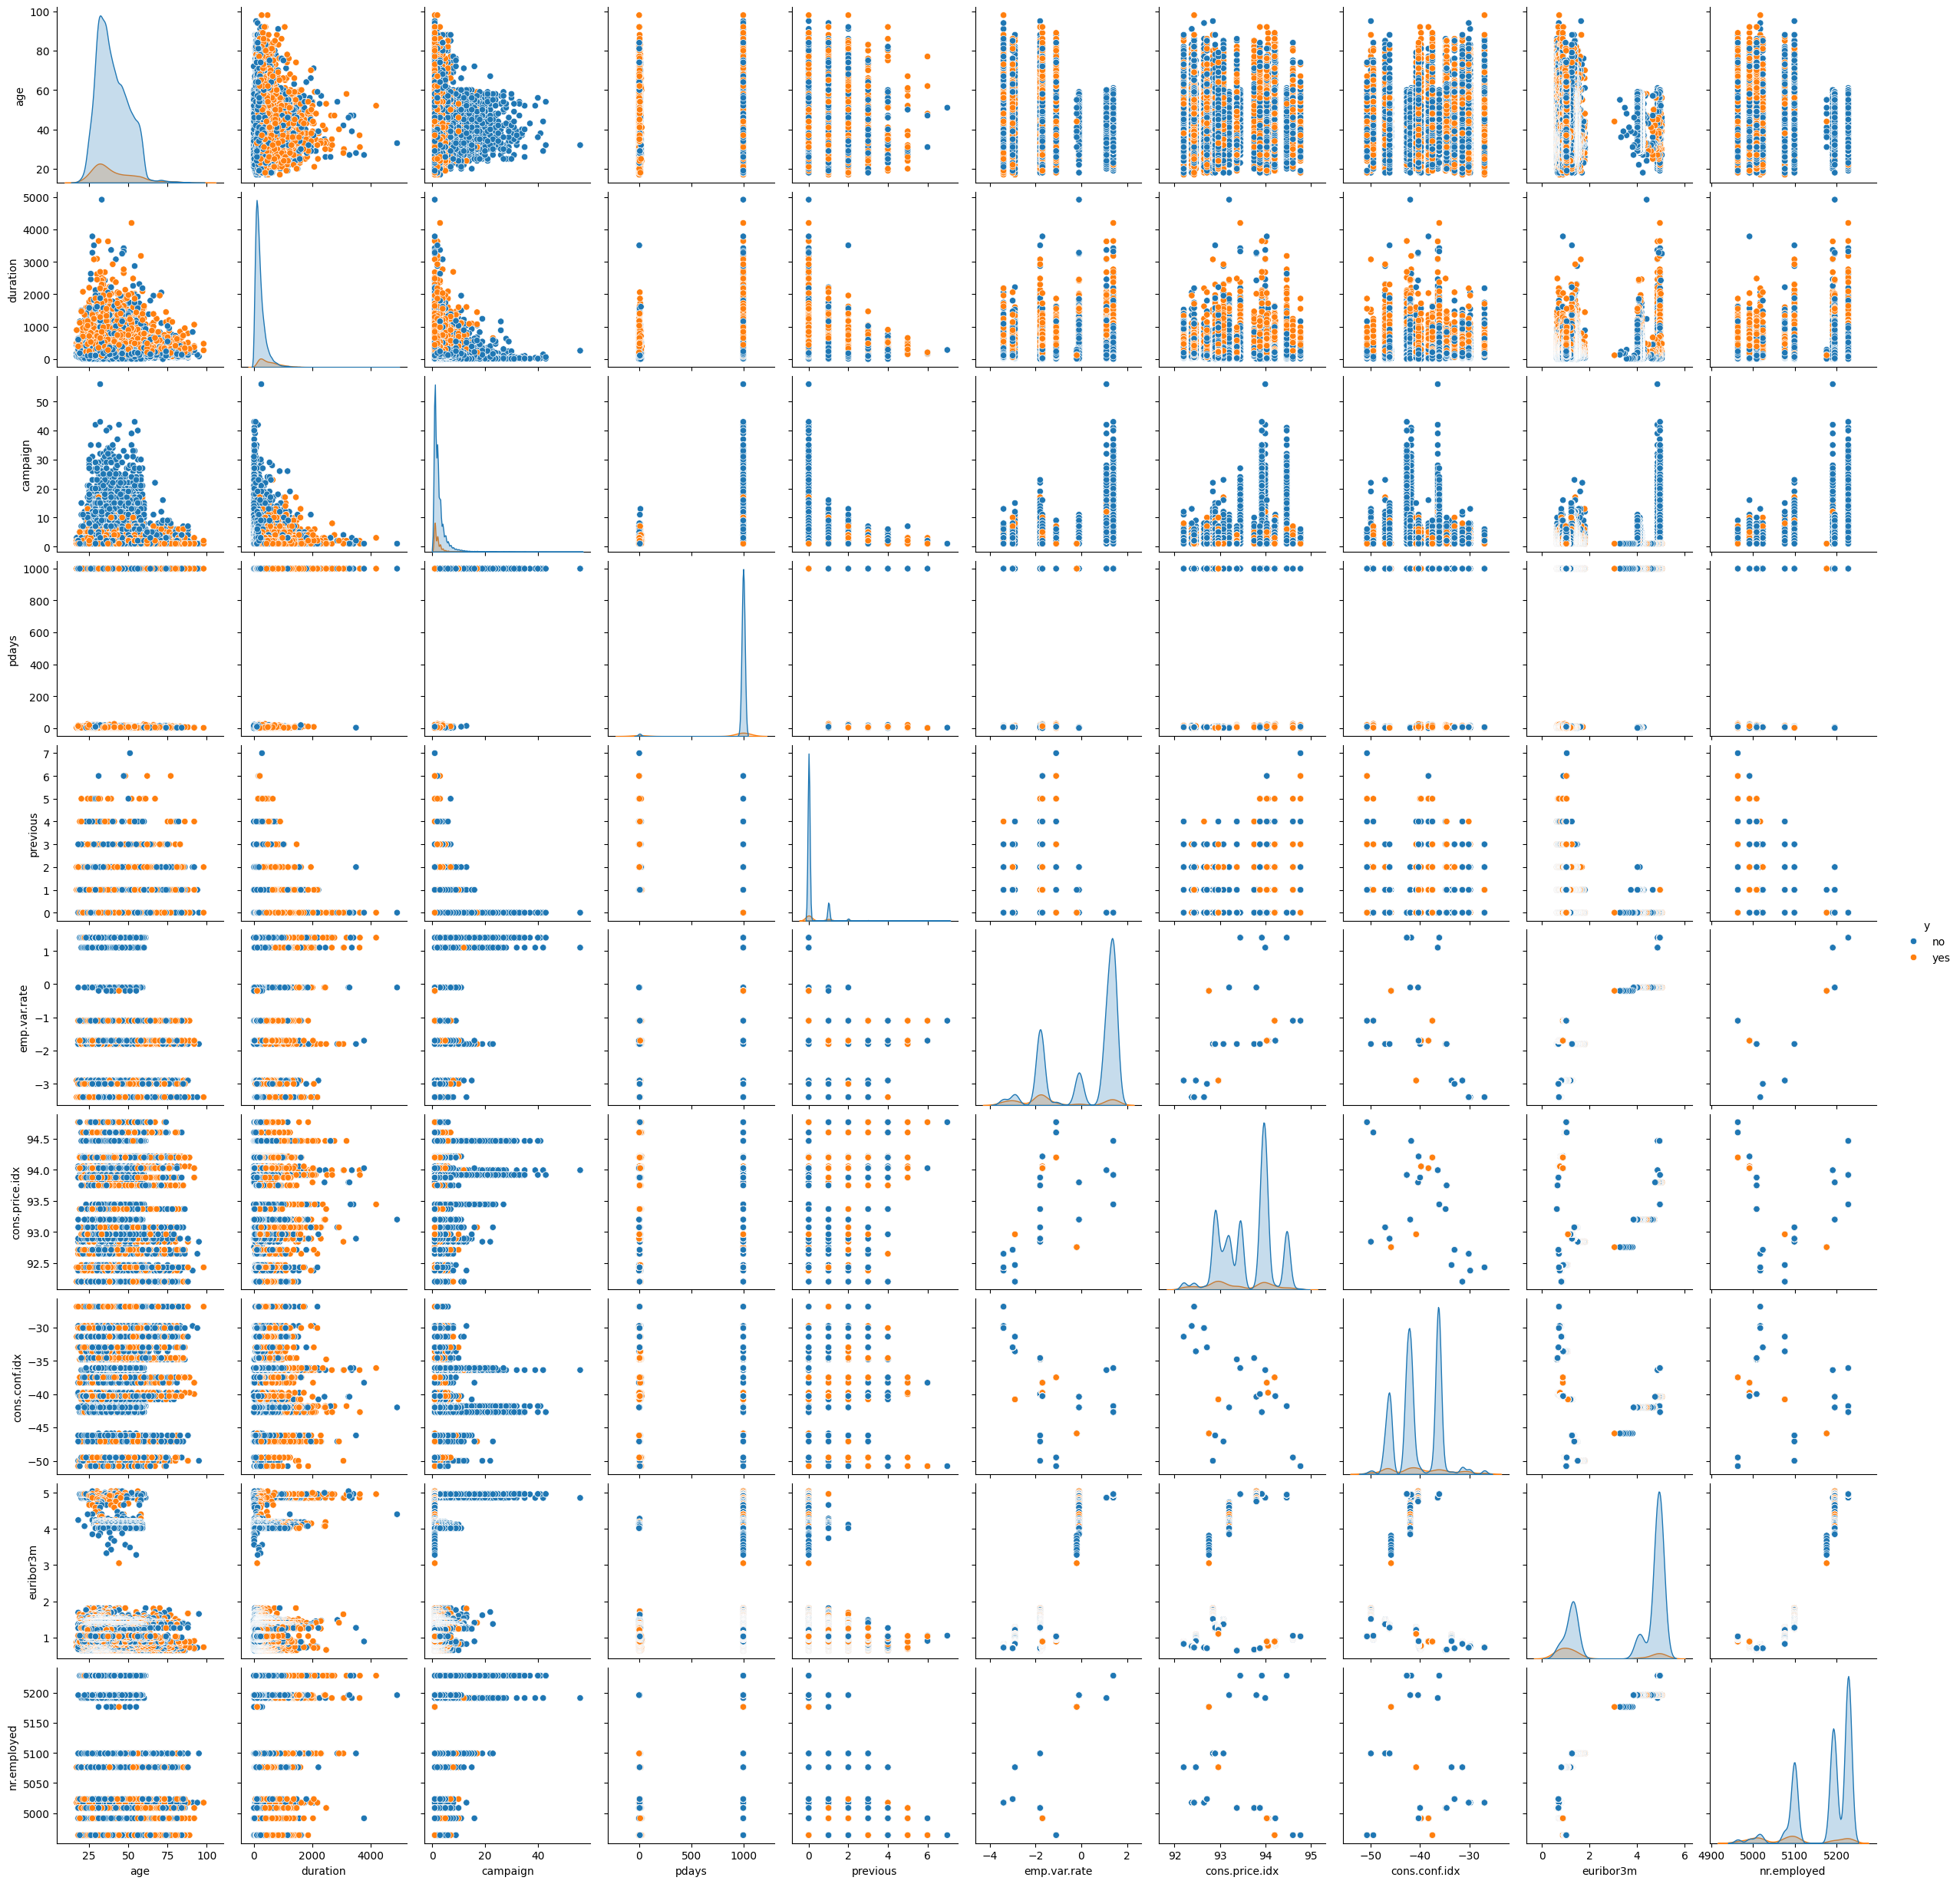

In [8]:
# Analisis bivariado (variables numéricas)
sns.pairplot(df_raw, hue='y')
plt.show()

| Variable Original                 | Transformación Sugerida                                         | Tipo de Acción                     | Justificación                                                            |
| --------------------------------- | --------------------------------------------------------------- | ---------------------------------- | ------------------------------------------------------------------------ |
| `duration`                        | ❌ Eliminar del modelo realista                                  | Eliminación                        | Genera *data leakage*. Solo usar en modelo benchmark.                    |
| `pdays`                           | `was_contacted_before = pdays != 999`                           | Binarización                       | 999 implica "no contactado", muy predominante. Mejora interpretabilidad. |
| `previous`                        | `had_previous_contact = previous > 0`                           | Binarización                       | La mayoría son 0. El valor 1 o más indica historial previo útil.         |
| `campaign`                        | Limitar máximo a 10 o agrupar en 3 categorías                   | Winsorización / Agrupación         | Evita ruido por outliers extremos (>40 contactos).                       |
| `age`                             | Agrupar en rangos etarios (ej: joven/adulto/senior)             | Discretización opcional            | Mejora claridad y posibles relaciones no lineales.                       |
| `emp.var.rate`                    | Mantener o escalar si modelo lo requiere                        | Escalado opcional                  | Influye en contexto económico. Escalar si usás regresión/SVM.            |
| `euribor3m`                       | Mantener o escalar si modelo lo requiere                        | Escalado opcional                  | Potente predictor indirecto. Puede reflejar tasas favorables.            |
| `nr.employed`                     | Mantener o escalar si modelo lo requiere                        | Escalado opcional                  | Altamente correlacionada con empleo y contexto.                          |
| `cons.price.idx`, `cons.conf.idx` | Mantener tal como están o combinar en índice                    | Conservación / Feature engineering | Potencial bajo individual, pero útiles en combinación macroeconómica.    |
| —                                 | `economic_condition_index` (combinación de 3–4 macroeconómicas) | Nueva variable derivada            | Permite capturar contexto global en una sola dimensión.                  |


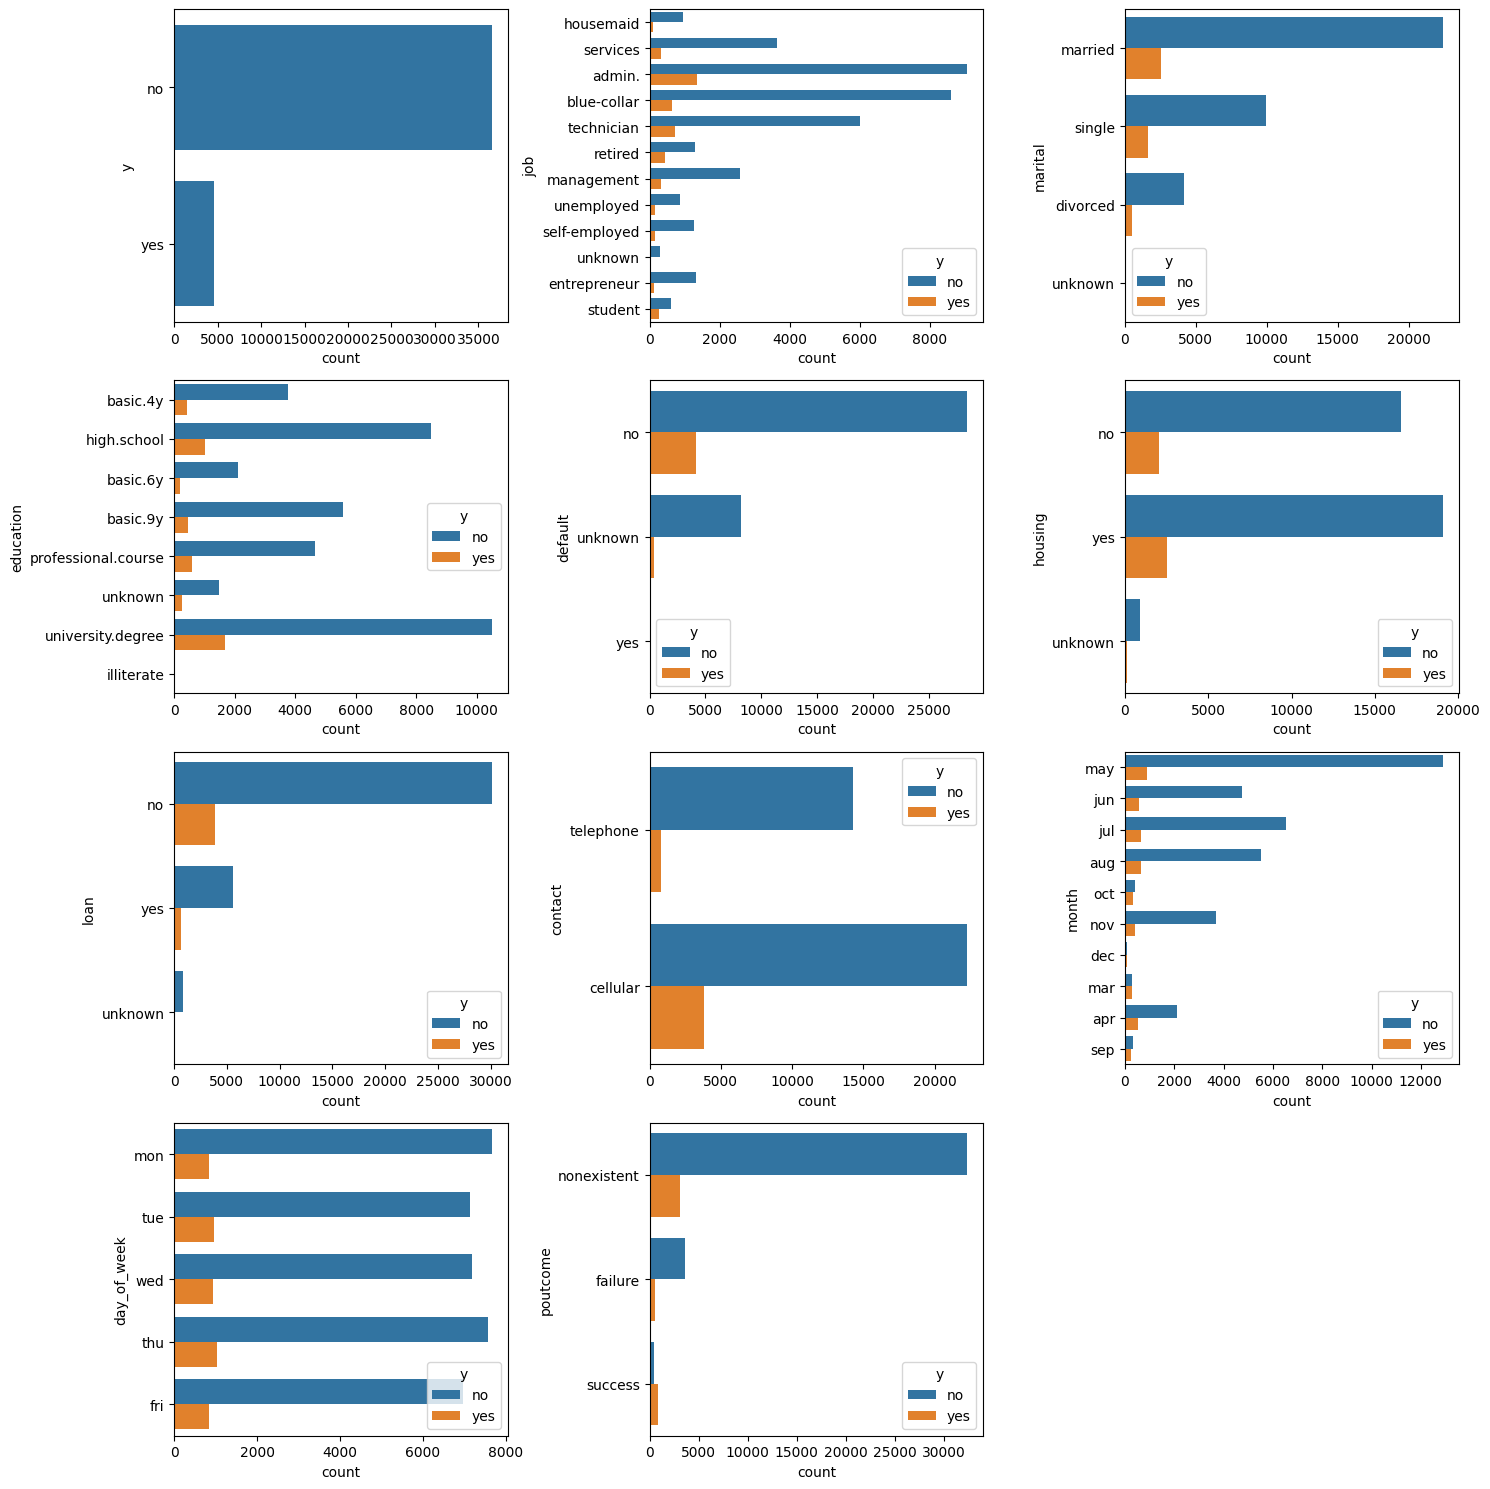

In [9]:
# Analisis bivariado (variables categóricas)
fig, ax = plt.subplots(4, 3, figsize=(15, 15))
sns.countplot(data= df_raw, y= 'y', ax= ax[0, 0])
sns.countplot(data= df_raw, y= 'job', hue='y', ax= ax[0, 1])
sns.countplot(data= df_raw, y= 'marital', hue='y', ax= ax[0, 2])
sns.countplot(data= df_raw, y= 'education', hue='y', ax= ax[1, 0])
sns.countplot(data= df_raw, y= 'default', hue='y', ax= ax[1, 1])
sns.countplot(data= df_raw, y= 'housing', hue='y', ax= ax[1, 2])
sns.countplot(data= df_raw, y= 'loan', hue='y', ax= ax[2, 0])
sns.countplot(data= df_raw, y= 'contact', hue='y', ax= ax[2, 1])
sns.countplot(data= df_raw, y= 'month', hue='y', ax= ax[2, 2])
sns.countplot(data= df_raw, y= 'day_of_week', hue='y', ax= ax[3, 0])
sns.countplot(data= df_raw, y= 'poutcome', hue='y', ax= ax[3, 1])

fig.delaxes(ax[3, 2])
plt.tight_layout()
plt.show()

| Variable Original | Comportamiento Observado en Bivariado                                          | Estrategia Sugerida                                 | Justificación                                                                |
| ----------------- | ------------------------------------------------------------------------------ | --------------------------------------------------- | ---------------------------------------------------------------------------- |
| `job`             | Algunas profesiones (student, retired, admin.) tienen mayor tasa de conversión | Mantener o reagrupar por sector (white/blue collar) | Mejora interpretabilidad y puede reducir dimensionalidad en modelos lineales |
| `marital`         | Leve mayor proporción de “yes” en single/divorced vs. married                  | Mantener sin cambios                                | Segmentación relevante; podría tener interacción con `age` o `education`     |
| `education`       | Mayor proporción de “yes” en university.degree y professional.course           | Mantener. Considerar codificación ordinal           | Puede tener relación con propensión al ahorro/inversión                      |
| `default`         | Proporción de “yes” baja en todas las clases; muchos unknown                   | Eliminar o reagrupar unknown                        | Poco poder predictivo y valores poco informativos                            |
| `housing`         | Quienes tienen préstamo hipotecario tienden a decir más “no”                   | Mantener. Tratar unknown como categoría             | Puede reflejar carga financiera que afecta decisión                          |
| `loan`            | Quienes no tienen préstamo personal muestran más “yes”                         | Mantener. Tratar unknown como categoría             | Similar lógica que housing. Útil para segmentar perfiles financieros         |
| `contact`         | Cellular tiene notablemente más “yes” que telephone                            | Mantener como está                                  | Indicador claro de canal más efectivo                                        |
| `month`           | Altas tasas de “yes” en meses menos activos (mar, apr, dec, sep)               | Agrupar por trimestre o mantener y codificar        | Riesgo de sesgo de campaña; pero puede tener valor temporal importante       |
| `day_of_week`     | Distribución uniforme, sin patrón evidente                                     | Eliminar (opcional)                                 | Poco poder predictivo aparente                                               |
| `poutcome`        | Alta proporción de “yes” en success; nonexistent domina en cantidad            | Mantener y aplicar one-hot encoding                 | Variable con alta información sobre historial efectivo                       |


## Análisis de correlación

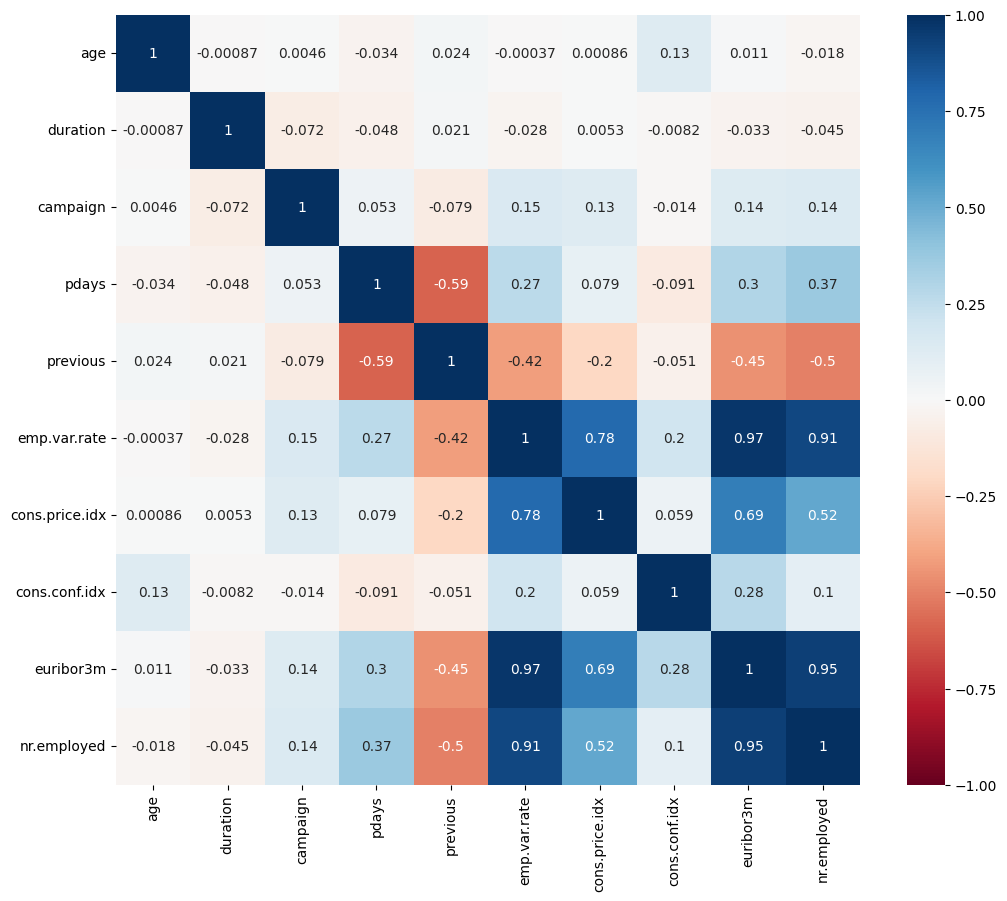

In [10]:
# Análisis de Correlación
plt.figure(figsize=(12, 10))
sns.heatmap(df_raw.select_dtypes('number').corr(), vmin= -1, vmax= 1, annot= True, cmap='RdBu')
plt.show()

## Análisis

| Variables Involucradas            | Valor de Correlación | Tipo de Acción                               | Justificación                                                                                                                                                   |
| --------------------------------- | -------------------- | -------------------------------------------- | --------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| `emp.var.rate` & `euribor3m`      | **0.97**             | Reducción de colinealidad (quedarse con una) | Altísima correlación → aportan casi la misma información. Mantener solo una o combinar.                                                                         |
| `emp.var.rate` & `nr.employed`    | **0.91**             | Igual que arriba                             | También están fuertemente ligadas al contexto macroeconómico. Se pueden fusionar en un índice.                                                                  |
| `euribor3m` & `nr.employed`       | **0.95**             | Igual que arriba                             | Si se usa regresión o SVM, esta multicolinealidad puede generar inestabilidad en el modelo.                                                                     |
| `emp.var.rate` & `cons.price.idx` | **0.78**             | Evaluar reducción de dimensionalidad         | Relación moderada-alta. Si se agrupan variables macro en un solo índice, esta puede formar parte.                                                               |
| `pdays` & `previous`              | **-0.59**            | Considerar transformar ambas                 | Relación negativa esperable (más días desde último contacto → menos contactos anteriores). Se pueden usar como `was_contacted_before` y `had_previous_contact`. |
| `previous` & `campaign`           | **-0.08**            | Mantener ambas                               | Correlación muy baja. Aportan información distinta.                                                                                                             |
| Resto de combinaciones            | < ±0.15              | Mantener                                     | Baja colinealidad. Aportan información independiente.                                                                                                           |


## 2. Procesamiento de los datos

### Estrategia de Transformación de Variables

| Variable Original | Transformación Aplicada                                                                                        | Tipo de Acción           | Justificación                                                 |
| ----------------- | -------------------------------------------------------------------------------------------------------------- | ------------------------ | ------------------------------------------------------------- |
| `duration`        | ❌ Eliminar                                                                                                     | Eliminación              | Provoca *data leakage* (conocida post-llamada).               |
| `age`             | Crear rangos de edad (0: 17–25, ..., 5: 65+)                                                                   | Discretización (binning) | Mejora interpretabilidad y capta no linealidades.             |
| `campaign`        | Limitar a un máximo de 7 (winsorización)                                                                       | Reducción de outliers    | Evita distorsión por insistencia excesiva.                    |
| `pdays`           | `prev_contacted` 0: yes, 1: 999 = no                                                                      | Binarización             | Captura si el cliente fue contactado antes.                   |
| `previous`        | `had_contact` 1: yes > 0; 0: yes = 0                                                                           | Binarización             | Indica si el cliente respondió a campañas anteriores.         |
| `emp.var.rate`    | Mantener sin cambios                                                                                           | Conservación directa     | Variable económica clave. No requiere transformación.         |
| `euribor3m`       | Incluir en índice `economic_index`                                                                             | Feature engineering      | Alta colinealidad. Mejor usar valor combinado.                |
| `nr.employed`     | Mantener sin cambios                                                                                           | Conservación directa     | Complementa el contexto económico.                            |
| `cons.price.idx`  | Incluir en índice `economic_index`                                                                             | Feature engineering      | Moderada correlación con otras macroeconómicas.               |
| `cons.conf.idx`   | Incluir en índice `economic_index`                                                                             | Feature engineering      | Aporta al sentimiento económico general.                      |
| `job`             | Reagrupar en sectores:<br>1: manual (blue-collar, etc.)<br>2: profesional<br>3: sin actividad<br>4: otros      | Binning semántico        | Reduce dimensionalidad sin perder significado económico.      |
| `marital`         | Codificación:<br>0: single<br>1: married<br>2: divorced/unknown                                                | Codificación ordinal     | Mantiene segmentación clave.                                  |
| `education`       | Codificación ordinal:<br>0: illiterate ... 6: university.degree                                                | Codificación ordinal     | Representa jerarquía educativa.                               |
| `default`         | Binarizar:<br>0: no<br>1: yes o unknown                                                                        | Binning simplificado     | Simplifica y evita pérdida por “unknown”.                     |
| `housing`         | Binarizar:<br>0: no<br>1: yes o unknown                                                                        | Binning simplificado     | Idem `default`. Captura carga financiera.                     |
| `loan`            | Binarizar:<br>0: no<br>1: yes o unknown                                                                        | Binning simplificado     | Refleja compromiso financiero.                                |
| `contact`         | Codificación binaria:<br>0: telephone<br>1: cellular                                                           | Binarización             | Canal importante en conversión.                               |
| `month`           | Agrupar en:<br>`Q1`: jan-mar<br>`Q2`: apr-jun<br>`Q3`: jul-sep<br>`Q4`: oct-dec<br>+ categoría separada: `may` | Agrupación personalizada | “may” tiene volumen atípico. Resto se agrupa estacionalmente. |
| `day_of_week`     | ❌ Eliminar                                                                                                     | Eliminación              | No aporta diferenciación predictiva.                          |
| `poutcome`        | One-hot encoding                                                                                               | Codificación categórica  | “success” tiene alto valor predictivo.                        |
| `y`               | Codificación binaria:<br>0: no<br>1: yes                                                                       | Codificación objetivo    | Requerido para clasificación supervisada.                     |


## Pre procesamiento

In [11]:
df_interim = (df_raw.copy())

df_interim['y'] = df_interim['y'].map({'no':0, 'yes':1})
df_interim['prev_contact'] = np.where(df_interim['pdays'] == 999, 1, 0)
df_interim['age_bin'] = pd.cut(df_interim['age'], bins=[16, 25, 35, 45, 55, 65, 100], labels=[0,1,2,3,4,5])
df_interim['age_bin'] = df_interim['age_bin'].astype('int64')
df_interim['campaign'] = df_interim['campaign']. clip(upper=7)

# PCA econ var
econ_vars = ['euribor3m', 'cons.price.idx', 'cons.conf.idx']
scaler = StandardScaler()
econ_scaled = scaler.fit_transform(df_interim[econ_vars])
pca = PCA(n_components=1)
economic_index_pca = pca.fit_transform(econ_scaled)
df_interim['economic_index'] = economic_index_pca.flatten()
print("Varianza explicada por el componente principal:", pca.explained_variance_ratio_[0])
print("Cargas del PCA:", pca.components_[0])

job_mapping = {
    'blue-collar': 1, 'housemaid': 1, 'services': 1,
    'admin.': 2, 'management': 2, 'technician': 2, 'entrepreneur': 2, 'self-employed': 2,
    'student': 3, 'retired': 3, 'unemployed': 3,
    'unknown': 4
}
df_interim['job_group'] = df_interim['job'].map(job_mapping)
marital_mapping = {'single': 0, 'married': 1, 'divorced': 2, 'unknown': 2}
df_interim['marital_code'] = df_interim['marital'].map(marital_mapping)
education_mapping = {
    'illiterate': 0, 'basic.4y': 1, 'basic.6y': 2, 'basic.9y': 3,
    'high.school': 4, 'professional.course': 5, 'university.degree': 6, 'unknown': 3
}
df_interim['education_ord'] = df_interim['education'].map(education_mapping)

for col in ['default', 'housing', 'loan']:
    df_interim[col + '_bin'] = df_interim[col].replace({'no': 0, 'yes': 1, 'unknown': 1})

df_interim['contact_bin'] = df_interim['contact'].map({'telephone': 0, 'cellular': 1})
month_map = {
    'jan': 'Q1', 'feb': 'Q1', 'mar': 'Q1',
    'apr': 'Q2', 'may': 'MAY', 'jun': 'Q2',
    'jul': 'Q3', 'aug': 'Q3', 'sep': 'Q3',
    'oct': 'Q4', 'nov': 'Q4', 'dec': 'Q4'
}
df_interim['month_group'] = df_interim['month'].map(month_map)
df_interim = pd.get_dummies(df_interim, columns=['month_group'], prefix='month', drop_first=True)

df_interim = pd.get_dummies(df_interim, columns=['poutcome'], prefix='pout')

drop_cols = ['duration', 'age', 'pdays', 'previous', 'emp.var.rate', 'euribor3m', 'cons.price.idx', 'cons.conf.idx',
             'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week']

df_clean = df_interim.drop(columns=drop_cols)

df_clean.info()

Varianza explicada por el componente principal: 0.5880136328421817
Cargas del PCA: [0.69625242 0.6505816  0.30327569]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   campaign          41188 non-null  int64  
 1   nr.employed       41188 non-null  float64
 2   y                 41188 non-null  int64  
 3   prev_contact      41188 non-null  int64  
 4   age_bin           41188 non-null  int64  
 5   economic_index    41188 non-null  float64
 6   job_group         41188 non-null  int64  
 7   marital_code      41188 non-null  int64  
 8   education_ord     41188 non-null  int64  
 9   default_bin       41188 non-null  int64  
 10  housing_bin       41188 non-null  int64  
 11  loan_bin          41188 non-null  int64  
 12  contact_bin       41188 non-null  int64  
 13  month_Q1          41188 non-null  bool   
 14  month_Q2        

/tmp/ipykernel_3732/2975588587.py:35: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_interim[col + '_bin'] = df_interim[col].replace({'no': 0, 'yes': 1, 'unknown': 1})
/tmp/ipykernel_3732/2975588587.py:35: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_interim[col + '_bin'] = df_interim[col].replace({'no': 0, 'yes': 1, 'unknown': 1})
/tmp/ipykernel_3732/2975588587.py:35: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.in

In [12]:
df_clean.to_csv('../data/processed/bank_cleaned.csv', index=False)

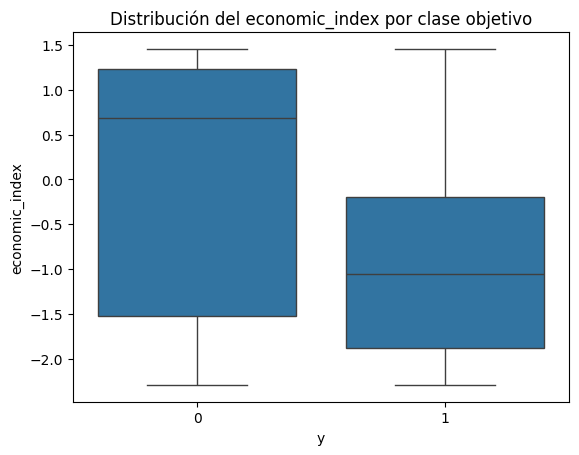

In [13]:
sns.boxplot(x='y', y='economic_index', data=df_interim)
plt.title('Distribución del economic_index por clase objetivo')
plt.show()

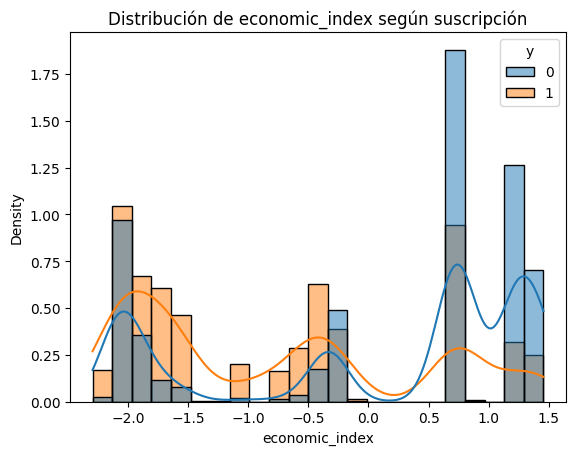

In [14]:
sns.histplot(data=df_interim, x='economic_index', hue='y', kde=True, stat='density', common_norm=False)
plt.title('Distribución de economic_index según suscripción')
plt.show()

## 3. EDA

In [15]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   campaign          41188 non-null  int64  
 1   nr.employed       41188 non-null  float64
 2   y                 41188 non-null  int64  
 3   prev_contact      41188 non-null  int64  
 4   age_bin           41188 non-null  int64  
 5   economic_index    41188 non-null  float64
 6   job_group         41188 non-null  int64  
 7   marital_code      41188 non-null  int64  
 8   education_ord     41188 non-null  int64  
 9   default_bin       41188 non-null  int64  
 10  housing_bin       41188 non-null  int64  
 11  loan_bin          41188 non-null  int64  
 12  contact_bin       41188 non-null  int64  
 13  month_Q1          41188 non-null  bool   
 14  month_Q2          41188 non-null  bool   
 15  month_Q3          41188 non-null  bool   
 16  month_Q4          41188 non-null  bool  

In [16]:
df_train, df_test = train_test_split(df_clean, test_size=0.2, random_state=42)

In [17]:
display(df_train.describe(include='number').T)
display(df_train.describe(include='bool').T)

,count,mean,std,min,25%,50%,75%,max
campaign,32950.0,2.336601,1.703541,1.00000,1.000000,2.000000,3.000000,7.000000
nr.employed,32950.0,5167.094049,72.354625,4963.60000,5099.100000,5191.000000,5228.100000,5228.100000
y,32950.0,0.112443,0.315916,0.00000,0.000000,0.000000,0.000000,1.000000
prev_contact,32950.0,0.963490,0.187558,0.00000,1.000000,1.000000,1.000000,1.000000
age_bin,32950.0,1.948042,1.070762,0.00000,1.000000,2.000000,3.000000,5.000000
economic_index,32950.0,0.001096,1.326802,-2.29337,-1.652778,0.679918,1.234678,1.454765
job_group,32950.0,1.753809,0.638932,1.00000,1.000000,2.000000,2.000000,4.000000
marital_code,32950.0,0.831897,0.608395,0.00000,0.000000,1.000000,1.000000,2.000000
education_ord,32950.0,4.112261,1.621446,0.00000,3.000000,4.000000,6.000000,6.000000
default_bin,32950.0,0.208194,0.406023,0.00000,0.000000,0.000000,0.000000,1.000000


,count,unique,top,freq
month_Q1,32950,2,False,32504
month_Q2,32950,2,False,26578
month_Q3,32950,2,False,21783
month_Q4,32950,2,False,28920
pout_failure,32950,2,False,29527
pout_nonexistent,32950,2,True,28437
pout_success,32950,2,False,31860


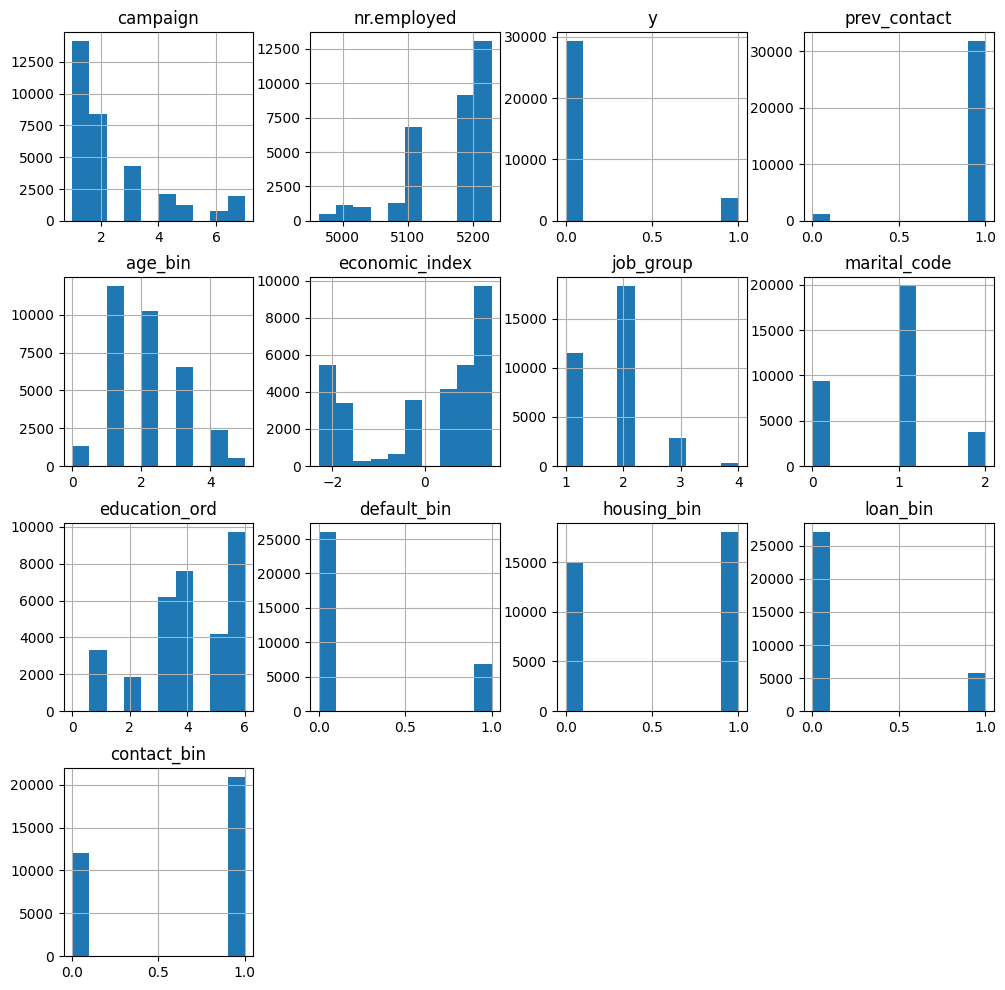

In [18]:
# 3.1 Analisis univariado
df_train.hist(figsize=(12,12))
plt.show()

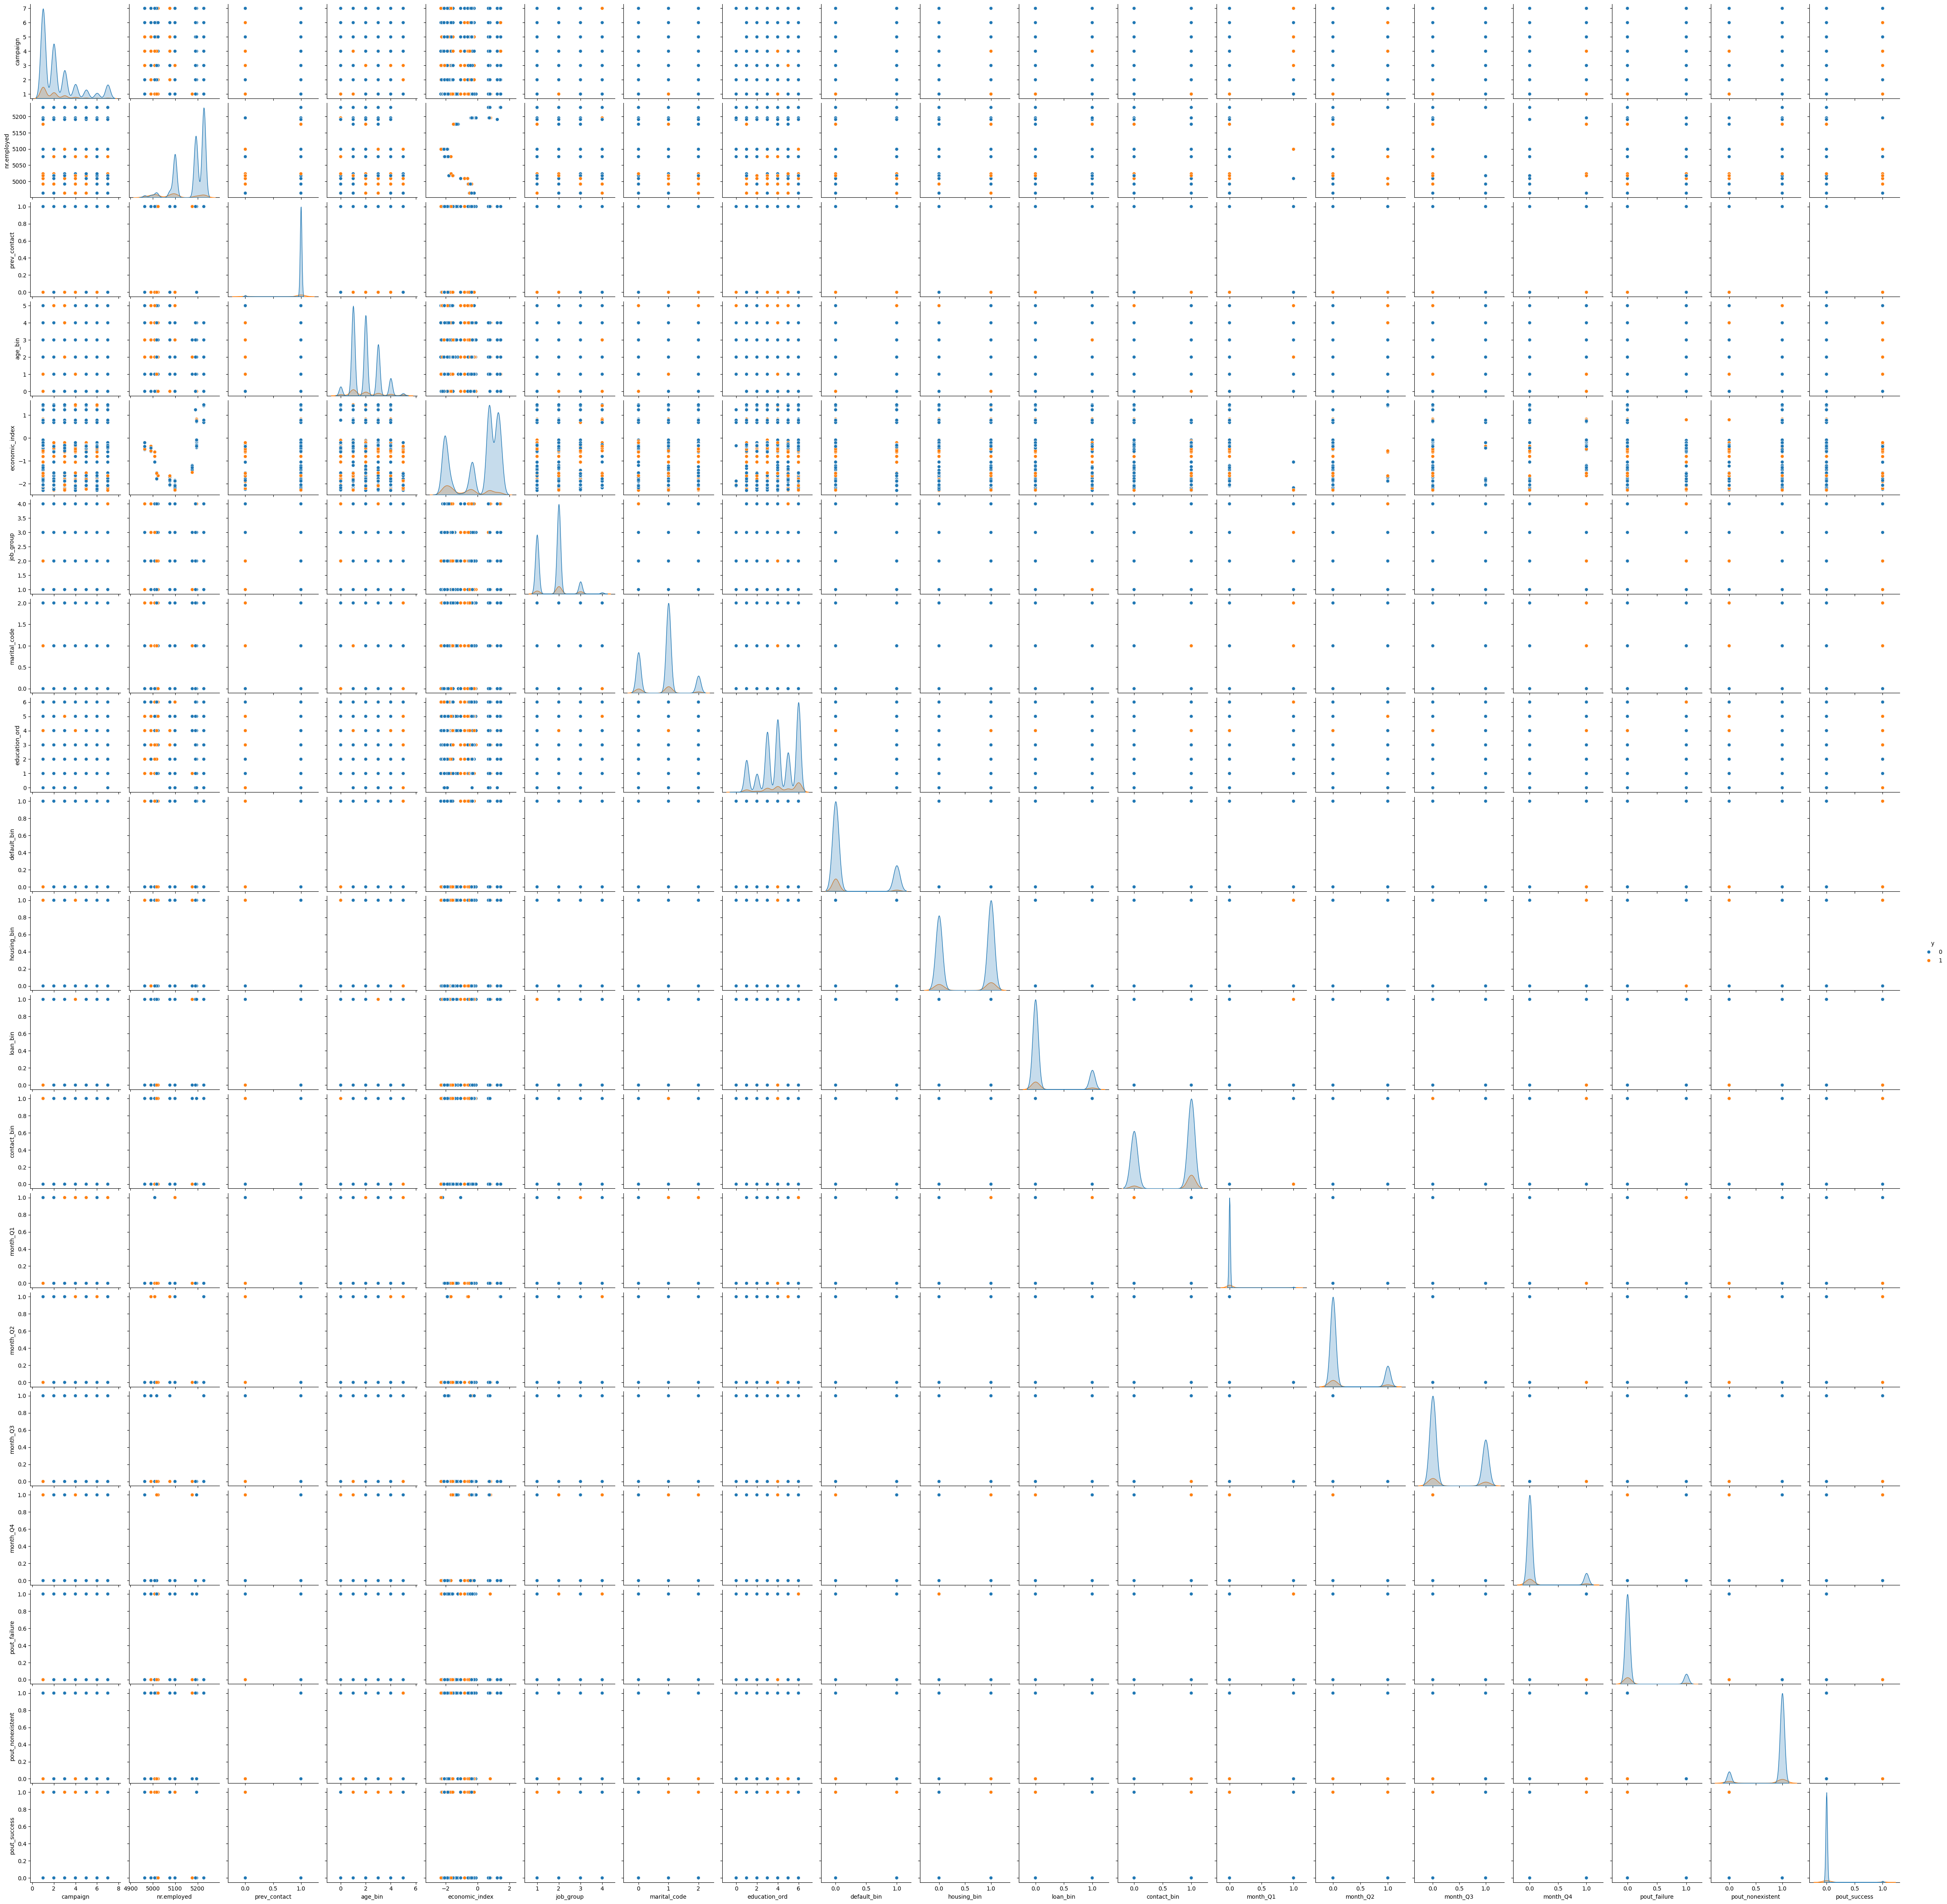

In [19]:
# 3.2 Analisis bivariado
sns.pairplot(df_train, hue='y')
plt.show()

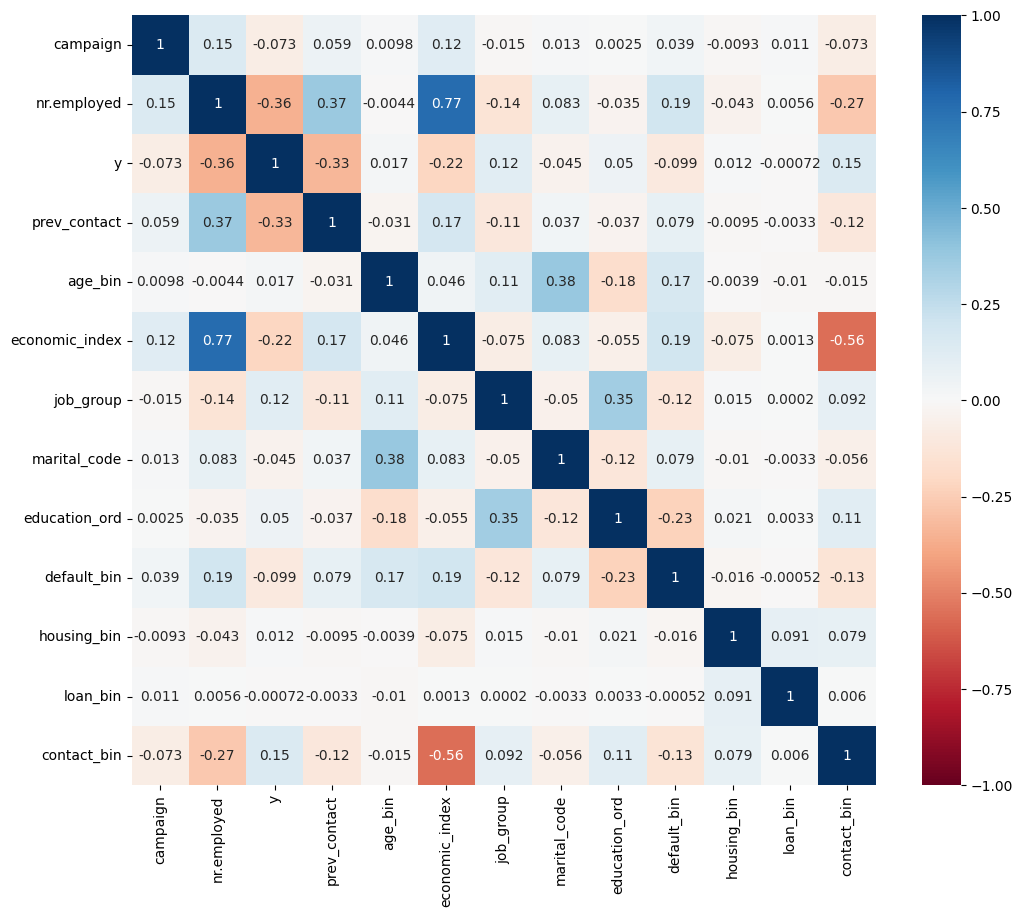

In [20]:
plt.figure(figsize=(12,10))
sns.heatmap(df_train.select_dtypes('number').corr(), vmin= -1, vmax= 1, annot= True, cmap='RdBu')
plt.show()

## 4. Entrenamiento de ML

utilizaremos los sigueintes modelos que serán evaluados según `ROC-AUC`, `f1-score` y `matriz de confusión`:

| Modelo                       | ¿Por qué?                                                                        |
| ---------------------------- | -------------------------------------------------------------------------------- |
| `RandomForestClassifier`     | Robusto, fácil de ajustar, interpreta bien interacciones y variables categóricas |
| `XGBoostClassifier`          | Altamente eficaz en tabulares, maneja bien desbalance, muy buen recall y AUC     |
| `LogisticRegression`         | Alta interpretabilidad, baseline estadístico ideal para comparar                 |
| `LightGBM`                   | Más rápido que XGBoost en grandes volúmenes, buena performance                   |

In [21]:
# Model ML
X_train = df_train.drop('y', axis=1).reset_index(drop= True)
y_train = df_train['y'].reset_index(drop= True)
X_test = df_test.drop('y', axis=1).reset_index(drop= True)
y_test = df_test['y'].reset_index(drop= True)

In [22]:
bool_cols = X_train.select_dtypes(include='bool').columns
X_train[bool_cols] = X_train[bool_cols].astype(int)
X_test[bool_cols] = X_test[bool_cols].astype(int)

## Random Forest

In [23]:
rf = RandomForestClassifier(
    random_state=42,
    class_weight='balanced',
    n_estimators=100
)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)
y_proba = rf.predict_proba(X_test)[:, 1]

print("🔎 Classification Report:\n", classification_report(y_test, y_pred))
print("🎯 ROC AUC Score:", roc_auc_score(y_test, y_proba))
print("🧾 Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

🔎 Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.94      0.93      7303
           1       0.41      0.30      0.35       935

    accuracy                           0.87      8238
   macro avg       0.66      0.62      0.64      8238
weighted avg       0.86      0.87      0.86      8238

🎯 ROC AUC Score: 0.7433403311656407
🧾 Confusion Matrix:
 [[6901  402]
 [ 652  283]]


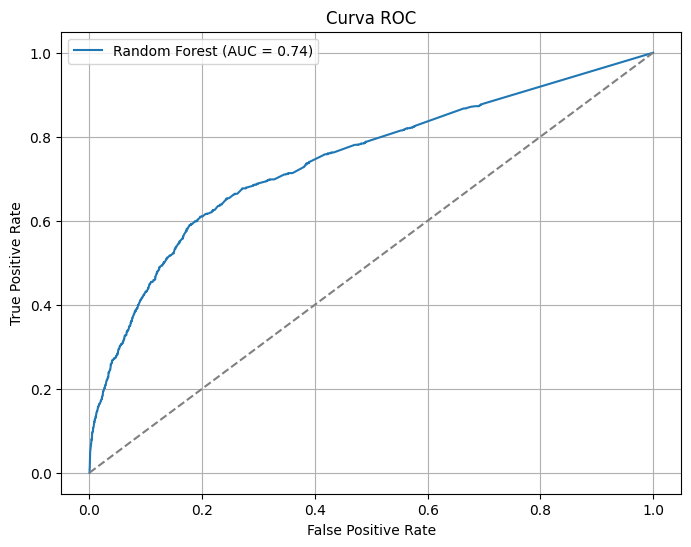

In [24]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = sk_auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'Random Forest (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Curva ROC')
plt.legend()
plt.grid(True)
plt.show()

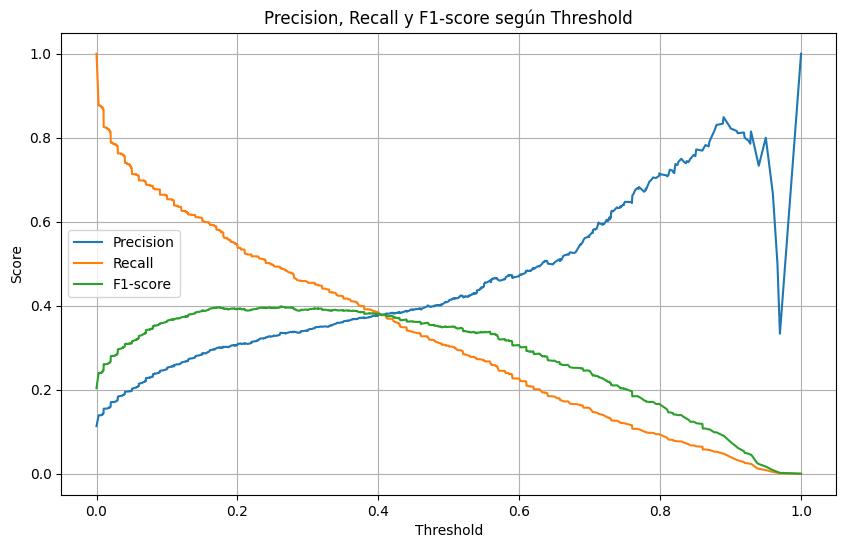

In [25]:
precision, recall, thresholds = precision_recall_curve(y_test, y_proba)

f1_scores = 2 * (precision * recall) / (precision + recall + 1e-8)

thresholds = np.append(thresholds, 1.0)

plt.figure(figsize=(10, 6))
plt.plot(thresholds, precision, label='Precision')
plt.plot(thresholds, recall, label='Recall')
plt.plot(thresholds, f1_scores, label='F1-score')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision, Recall y F1-score según Threshold')
plt.legend()
plt.grid(True)
plt.show()

In [26]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'class_weight': ['balanced']
}

grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    scoring='recall',
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_rf.fit(X_train, y_train)

print("🔍 Best Params:", grid_rf.best_params_)
print("🎯 Best F1-score:", grid_rf.best_score_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


🔍 Best Params: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}
🎯 Best F1-score: 0.6099865047233468


In [27]:
best_rf = RandomForestClassifier(
    class_weight='balanced',
    max_depth=10,
    min_samples_leaf=2,
    min_samples_split=2,
    n_estimators=100,
    random_state=42
)
best_rf.fit(X_train, y_train)

y_pred_best_rf = best_rf.predict(X_test)
y_proba_best_rf = best_rf.predict_proba(X_test)[:, 1]

print("🔎 Classification Report:\n", classification_report(y_test, y_pred_best_rf))
print("🎯 ROC AUC Score:", roc_auc_score(y_test, y_proba_best_rf))
print("🧾 Confusion Matrix:\n", confusion_matrix(y_test, y_pred_best_rf))

report_rf = classification_report(y_test, y_pred_best_rf, output_dict=True)
recall_rf = report_rf['1']['recall']
precision_rf = report_rf['1']['precision']
f1_rf = report_rf['1']['f1-score']
auc_rf = roc_auc_score(y_test, y_proba_best_rf)

print("📌 Recall:", round(recall_rf, 4))
print("📌 Precision:", round(precision_rf, 4))
print("📌 F1-score:", round(f1_rf, 4))
print("📌 ROC AUC:", round(auc_rf, 4))

🔎 Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.89      0.91      7303
           1       0.40      0.58      0.47       935

    accuracy                           0.85      8238
   macro avg       0.67      0.73      0.69      8238
weighted avg       0.88      0.85      0.86      8238

🎯 ROC AUC Score: 0.7852182935589432
🧾 Confusion Matrix:
 [[6488  815]
 [ 394  541]]
📌 Recall: 0.5786
📌 Precision: 0.399
📌 F1-score: 0.4723
📌 ROC AUC: 0.7852


## XGBoost

In [28]:
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

xgb_model = xgb.XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42,
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum()
)

xgb_model.fit(X_train, y_train)

y_pred = xgb_model.predict(X_test)
y_proba = xgb_model.predict_proba(X_test)[:, 1]

print("🔎 Classification Report:\n", classification_report(y_test, y_pred))
print("🎯 ROC AUC Score:", roc_auc_score(y_test, y_proba))
print("🧾 Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

🔎 Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.86      0.90      7303
           1       0.35      0.56      0.43       935

    accuracy                           0.83      8238
   macro avg       0.64      0.71      0.66      8238
weighted avg       0.87      0.83      0.85      8238

🎯 ROC AUC Score: 0.7485572188119893
🧾 Confusion Matrix:
 [[6307  996]
 [ 409  526]]


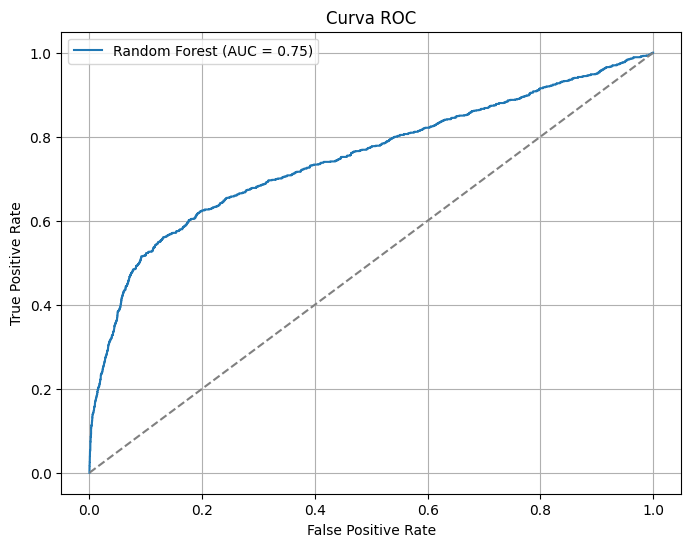

In [29]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = sk_auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'Random Forest (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Curva ROC')
plt.legend()
plt.grid(True)
plt.show()

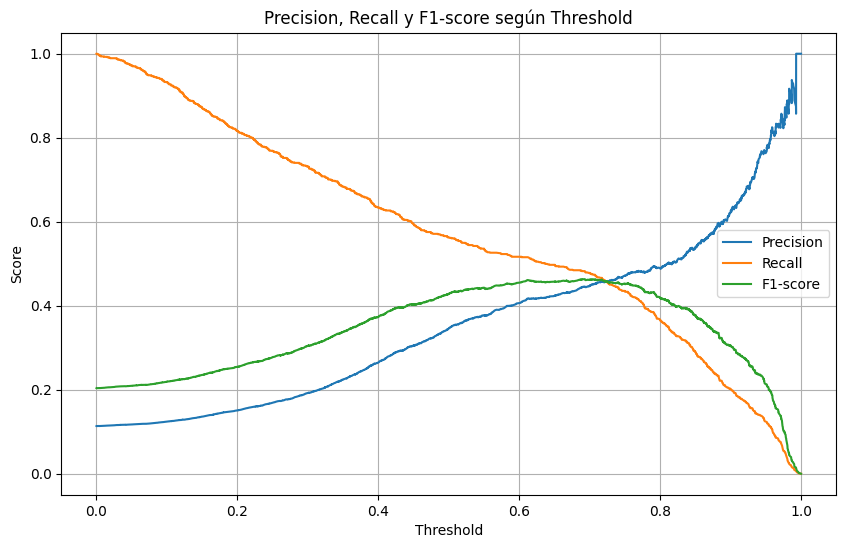

In [30]:
precision, recall, thresholds = precision_recall_curve(y_test, y_proba)

f1_scores = 2 * (precision * recall) / (precision + recall + 1e-8)

thresholds = np.append(thresholds, 1.0)


plt.figure(figsize=(10, 6))
plt.plot(thresholds, precision, label='Precision')
plt.plot(thresholds, recall, label='Recall')
plt.plot(thresholds, f1_scores, label='F1-score')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision, Recall y F1-score según Threshold')
plt.legend()
plt.grid(True)
plt.show()

In [31]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'scale_pos_weight': [(y_train == 0).sum() / (y_train == 1).sum()]
}

xgb_clf = xgb.XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42
)

grid_search = GridSearchCV(
    estimator=xgb_clf,
    param_grid=param_grid,
    scoring='recall',
    cv=5,
    verbose=1,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

# Resultados
print("🔍 Best Parameters:", grid_search.best_params_)
print("🎯 Best Recall (CV):", grid_search.best_score_)

Fitting 5 folds for each of 48 candidates, totalling 240 fits


🔍 Best Parameters: {'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'scale_pos_weight': np.float64(7.893387314439946), 'subsample': 0.8}
🎯 Best Recall (CV): 0.6448043184885289


In [32]:
best_xgb = grid_search.best_estimator_

y_pred_best_xgb = best_xgb.predict(X_test)
y_proba_best_xgb = best_xgb.predict_proba(X_test)[:, 1]

print("🔎 Classification Report:\n", classification_report(y_test, y_pred_best_xgb))
print("🎯 ROC AUC Score:", roc_auc_score(y_test, y_proba_best_xgb))
print("🧾 Confusion Matrix:\n", confusion_matrix(y_test, y_pred_best_xgb))

report_xgb = classification_report(y_test, y_pred_best_xgb, output_dict=True)
recall_xgb = report_xgb['1']['recall']
precision_xgb = report_xgb['1']['precision']
f1_xgb = report_xgb['1']['f1-score']
auc_xgb = roc_auc_score(y_test, y_proba_best_xgb)

print("📌 Recall:", round(recall_xgb, 4))
print("📌 Precision:", round(precision_xgb, 4))
print("📌 F1-score:", round(f1_xgb, 4))
print("📌 ROC AUC:", round(auc_xgb, 4))

🔎 Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.86      0.90      7303
           1       0.36      0.63      0.46       935

    accuracy                           0.83      8238
   macro avg       0.65      0.74      0.68      8238
weighted avg       0.88      0.83      0.85      8238

🎯 ROC AUC Score: 0.7921676755798108
🧾 Confusion Matrix:
 [[6258 1045]
 [ 347  588]]
📌 Recall: 0.6289
📌 Precision: 0.3601
📌 F1-score: 0.4579
📌 ROC AUC: 0.7922


## Regresión Logítica

In [33]:
logreg = LogisticRegression(
    class_weight='balanced',
    solver='liblinear',
    random_state=42
)

logreg.fit(X_train, y_train)

y_pred = logreg.predict(X_test)
y_proba = logreg.predict_proba(X_test)[:, 1]

print("🔎 Classification Report:\n", classification_report(y_test, y_pred))
print("🎯 ROC AUC Score:", roc_auc_score(y_test, y_proba))
print("🧾 Confusion Matrix:\n", confusion_matrix(y_test, y_pred))


🔎 Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.83      0.88      7303
           1       0.32      0.63      0.42       935

    accuracy                           0.81      8238
   macro avg       0.63      0.73      0.65      8238
weighted avg       0.87      0.81      0.83      8238

🎯 ROC AUC Score: 0.7754307254875111
🧾 Confusion Matrix:
 [[6055 1248]
 [ 348  587]]


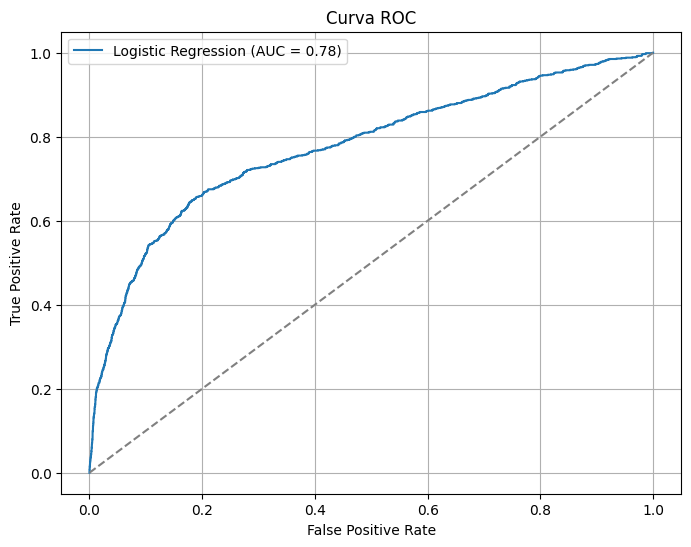

In [34]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc_value = sk_auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {roc_auc_value:.2f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Curva ROC')
plt.legend()
plt.grid(True)
plt.show()

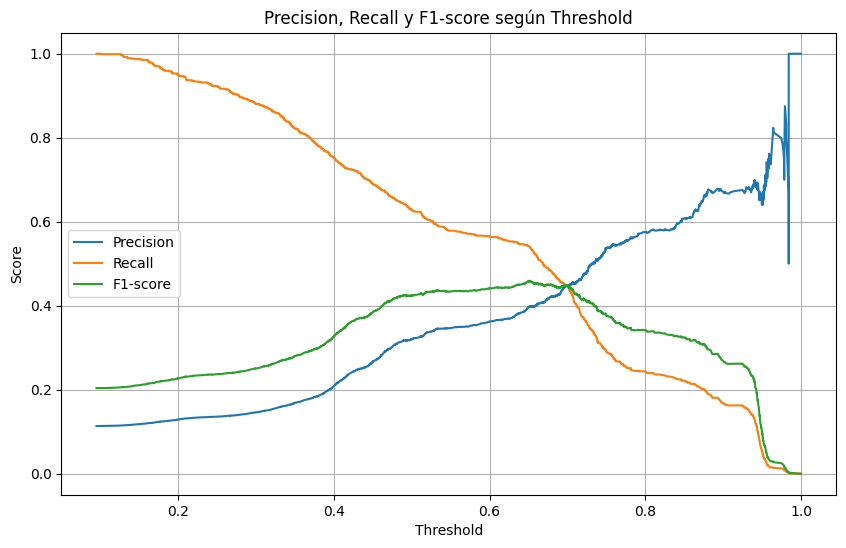

In [35]:
precision, recall, thresholds = precision_recall_curve(y_test, y_proba)

f1_scores = 2 * (precision * recall) / (precision + recall + 1e-8)

thresholds = np.append(thresholds, 1.0)


plt.figure(figsize=(10, 6))
plt.plot(thresholds, precision, label='Precision')
plt.plot(thresholds, recall, label='Recall')
plt.plot(thresholds, f1_scores, label='F1-score')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision, Recall y F1-score según Threshold')
plt.legend()
plt.grid(True)
plt.show()

In [36]:
param_grid = {
    'C': [0.01, 0.1, 1, 10],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear'],
    'class_weight': ['balanced']
}

logreg_base = LogisticRegression(random_state=42, max_iter=2000)

grid_search = GridSearchCV(
    estimator=logreg_base,
    param_grid=param_grid,
    scoring='recall',
    cv=5,
    verbose=1,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("🔍 Best Params:", grid_search.best_params_)
print("🎯 Best Recall (CV):", grid_search.best_score_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits


🔍 Best Params: {'C': 0.01, 'class_weight': 'balanced', 'penalty': 'l2', 'solver': 'liblinear'}
🎯 Best Recall (CV): 0.67638326585695


In [37]:
best_logreg = grid_search.best_estimator_

y_pred_best_log = best_logreg.predict(X_test)
y_proba_best_log = best_logreg.predict_proba(X_test)[:, 1]


print("🔎 Classification Report:\n", classification_report(y_test, y_pred_best_log))
print("🎯 ROC AUC Score:", roc_auc_score(y_test, y_proba_best_log))
print("🧾 Confusion Matrix:\n", confusion_matrix(y_test, y_pred_best_log))

report_log = classification_report(y_test, y_pred_best_log, output_dict=True)
recall_log = report_log['1']['recall']
precision_log = report_log['1']['precision']
f1_log = report_log['1']['f1-score']
auc_log = roc_auc_score(y_test, y_proba_best_log)

print("📌 Recall:", round(recall_log, 4))
print("📌 Precision:", round(precision_log, 4))
print("📌 F1-score:", round(f1_log, 4))
print("📌 ROC AUC:", round(auc_log, 4))

🔎 Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.75      0.84      7303
           1       0.26      0.68      0.37       935

    accuracy                           0.74      8238
   macro avg       0.60      0.71      0.60      8238
weighted avg       0.87      0.74      0.78      8238

🎯 ROC AUC Score: 0.764154134884133
🧾 Confusion Matrix:
 [[5462 1841]
 [ 298  637]]
📌 Recall: 0.6813
📌 Precision: 0.2571
📌 F1-score: 0.3733
📌 ROC AUC: 0.7642


## LightGBM

In [38]:
lgb_model = LGBMClassifier(
    random_state=42,
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum()
)

lgb_model.fit(X_train, y_train)


y_pred = lgb_model.predict(X_test)
y_proba = lgb_model.predict_proba(X_test)[:, 1]

print("🔎 Classification Report:\n", classification_report(y_test, y_pred))
print("🎯 ROC AUC Score:", roc_auc_score(y_test, y_proba))
print("🧾 Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

[LightGBM] [Info] Number of positive: 3705, number of negative: 29245
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002892 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 219
[LightGBM] [Info] Number of data points in the train set: 32950, number of used features: 19
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.112443 -> initscore=-2.066025
[LightGBM] [Info] Start training from score -2.066025
🔎 Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.87      0.91      7303
           1       0.38      0.61      0.47       935

    accuracy                           0.84      8238
   macro avg       0.66      0.74      0.69      8238
weighted avg       0.88      0.84      0.86      8238

🎯 ROC AUC Score: 0.7892372997398329
🧾 Confusion Matrix:
 [[6373  930]
 [ 360  575]]


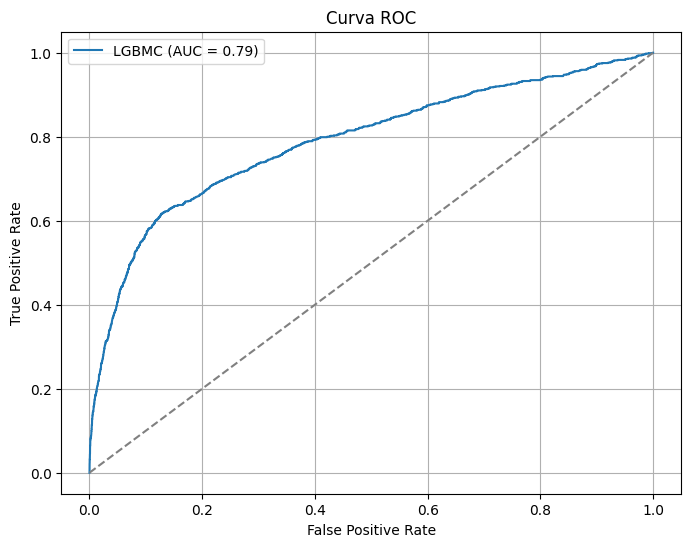

In [39]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc_value = sk_auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'LGBMC (AUC = {roc_auc_value:.2f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Curva ROC')
plt.legend()
plt.grid(True)
plt.show()


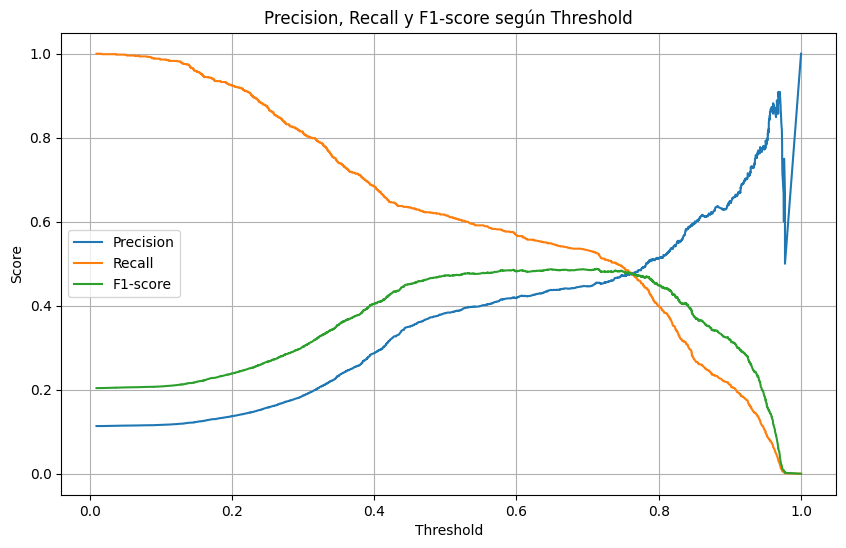

In [40]:
precision, recall, thresholds = precision_recall_curve(y_test, y_proba)

f1_scores = 2 * (precision * recall) / (precision + recall + 1e-8)

thresholds = np.append(thresholds, 1.0)


plt.figure(figsize=(10, 6))
plt.plot(thresholds, precision, label='Precision')
plt.plot(thresholds, recall, label='Recall')
plt.plot(thresholds, f1_scores, label='F1-score')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision, Recall y F1-score según Threshold')
plt.legend()
plt.grid(True)
plt.show()

In [41]:
param_grid = {
    'num_leaves': [31, 50],
    'max_depth': [-1, 10, 20],
    'learning_rate': [0.05, 0.1],
    'n_estimators': [100, 200],
    'scale_pos_weight': [(y_train == 0).sum() / (y_train == 1).sum()]
}

lgb_base = LGBMClassifier(random_state=42, force_col_wise=True)

grid_lgb = GridSearchCV(
    estimator=lgb_base,
    param_grid=param_grid,
    scoring='recall',
    cv=5,
    verbose=1,
    n_jobs=-1
)

grid_lgb.fit(X_train, y_train)

print("🔍 Best Params:", grid_lgb.best_params_)
print("🎯 Best Recall (CV):", grid_lgb.best_score_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
[LightGBM] [Info] Number of positive: 2964, number of negative: 23396
[LightGBM] [Info] Total Bins 218
[LightGBM] [Info] Number of data points in the train set: 26360, number of used features: 19
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.112443 -> initscore=-2.066025
[LightGBM] [Info] Start training from score -2.066025
[LightGBM] [Info] Number of positive: 2964, number of negative: 23396
[LightGBM] [Info] Total Bins 216
[LightGBM] [Info] Number of data points in the train set: 26360, number of used features: 19
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.112443 -> initscore=-2.066025
[LightGBM] [Info] Start training from score -2.066025
[LightGBM] [Info] Number of positive: 2964, number of negative: 23396
[LightGBM] [Info] Total Bins 217
[LightGBM] [Info] Number of data points in the train set: 26360, number of used features: 19
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.112443 -> initscore=-2.066025
[L

[LightGBM] [Info] Number of positive: 2964, number of negative: 23396
[LightGBM] [Info] Total Bins 218
[LightGBM] [Info] Number of data points in the train set: 26360, number of used features: 19
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.112443 -> initscore=-2.066025
[LightGBM] [Info] Start training from score -2.066025
[LightGBM] [Info] Number of positive: 2964, number of negative: 23396
[LightGBM] [Info] Total Bins 216
[LightGBM] [Info] Number of data points in the train set: 26360, number of used features: 19
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.112443 -> initscore=-2.066025
[LightGBM] [Info] Start training from score -2.066025
[LightGBM] [Info] Number of positive: 2964, number of negative: 23396
[LightGBM] [Info] Total Bins 217
[LightGBM] [Info] Number of data points in the train set: 26360, number of used features: 19
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.112443 -> initscore=-2.066025
[LightGBM] [Info] Start training from score -2.066025
[LightGBM]

/workspaces/FIUBA-IoT_Machine-Learning/.venv/lib/python3.12/site-packages/numpy/ma/core.py:2881: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


[LightGBM] [Info] Number of positive: 3705, number of negative: 29245
[LightGBM] [Info] Total Bins 219
[LightGBM] [Info] Number of data points in the train set: 32950, number of used features: 19
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.112443 -> initscore=-2.066025
[LightGBM] [Info] Start training from score -2.066025
🔍 Best Params: {'learning_rate': 0.05, 'max_depth': 10, 'n_estimators': 100, 'num_leaves': 31, 'scale_pos_weight': np.float64(7.893387314439946)}
🎯 Best Recall (CV): 0.6364372469635627


In [42]:
best_lgb = grid_lgb.best_estimator_

y_pred_best_lgb = best_lgb.predict(X_test)
y_proba_best_lgb = best_lgb.predict_proba(X_test)[:, 1]

print("🔎 Classification Report:\n", classification_report(y_test, y_pred_best_lgb))
print("🎯 ROC AUC Score:", roc_auc_score(y_test, y_proba_best_lgb))
print("🧾 Confusion Matrix:\n", confusion_matrix(y_test, y_pred_best_lgb))

report_lgb = classification_report(y_test, y_pred_best_lgb, output_dict=True)
recall_lgb = report_lgb['1']['recall']
precision_lgb = report_lgb['1']['precision']
f1_lgb = report_lgb['1']['f1-score']
auc_lgb = roc_auc_score(y_test, y_proba_best_lgb)

print("📌 Recall:", round(recall_lgb, 4))
print("📌 Precision:", round(precision_lgb, 4))
print("📌 F1-score:", round(f1_lgb, 4))
print("📌 ROC AUC:", round(auc_lgb, 4))

🔎 Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.87      0.91      7303
           1       0.38      0.62      0.47       935

    accuracy                           0.84      8238
   macro avg       0.67      0.75      0.69      8238
weighted avg       0.88      0.84      0.86      8238

🎯 ROC AUC Score: 0.7913964007173083
🧾 Confusion Matrix:
 [[6381  922]
 [ 358  577]]
📌 Recall: 0.6171
📌 Precision: 0.3849
📌 F1-score: 0.4741
📌 ROC AUC: 0.7914


## 5. Evaluación de modelos

In [43]:
comparacion_modelos = pd.DataFrame({
    'Modelo': ['RandomForest', 'LightGBM', 'LogisticReg', 'XGBoost'],
    'Recall (y=1)': [recall_rf, recall_lgb, recall_log, recall_xgb],
    'Precision (y=1)': [precision_rf, precision_lgb, precision_log, precision_xgb],
    'F1-score (y=1)': [f1_rf, f1_lgb, f1_log, f1_xgb],
    'ROC AUC': [auc_rf, auc_lgb, auc_log, auc_xgb],
})

comparacion_modelos_ordenada = comparacion_modelos.sort_values(by='Recall (y=1)', ascending=False)
display(comparacion_modelos_ordenada)

,Modelo,Recall (y=1),Precision (y=1),F1-score (y=1),ROC AUC
2,LogisticReg,0.681283,0.257062,0.373279,0.764154
3,XGBoost,0.628877,0.360073,0.457944,0.792168
1,LightGBM,0.617112,0.384923,0.474117,0.791396
0,RandomForest,0.578610,0.398968,0.472283,0.785218


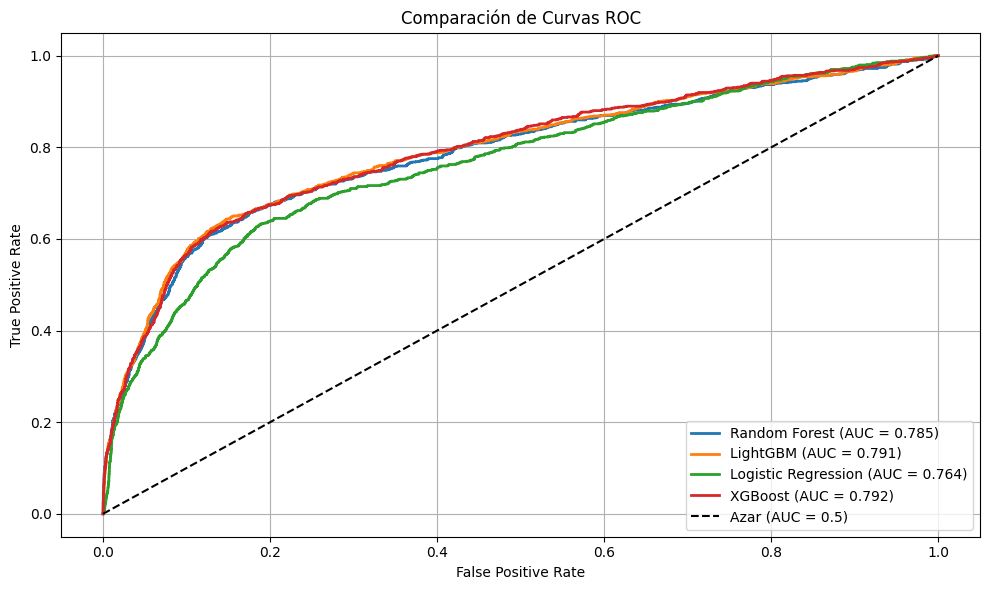

In [44]:
fpr_rf, tpr_rf, _ = roc_curve(y_test, best_rf.predict_proba(X_test)[:, 1])
fpr_lgb, tpr_lgb, _ = roc_curve(y_test, best_lgb.predict_proba(X_test)[:, 1])
fpr_log, tpr_log, _ = roc_curve(y_test, best_logreg.predict_proba(X_test)[:, 1])
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, best_xgb.predict_proba(X_test)[:, 1])

roc_auc_rf = sk_auc(fpr_rf, tpr_rf)
roc_auc_lgb = sk_auc(fpr_lgb, tpr_lgb)
roc_auc_log = sk_auc(fpr_log, tpr_log)
roc_auc_xgb = sk_auc(fpr_xgb, tpr_xgb)

plt.figure(figsize=(10, 6))
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_rf:.3f})', linewidth=2)
plt.plot(fpr_lgb, tpr_lgb, label=f'LightGBM (AUC = {roc_auc_lgb:.3f})', linewidth=2)
plt.plot(fpr_log, tpr_log, label=f'Logistic Regression (AUC = {roc_auc_log:.3f})', linewidth=2)
plt.plot(fpr_xgb, tpr_xgb, label=f'XGBoost (AUC = {roc_auc_xgb:.3f})', linewidth=2)

plt.plot([0, 1], [0, 1], 'k--', label='Azar (AUC = 0.5)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Comparación de Curvas ROC')
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.show()

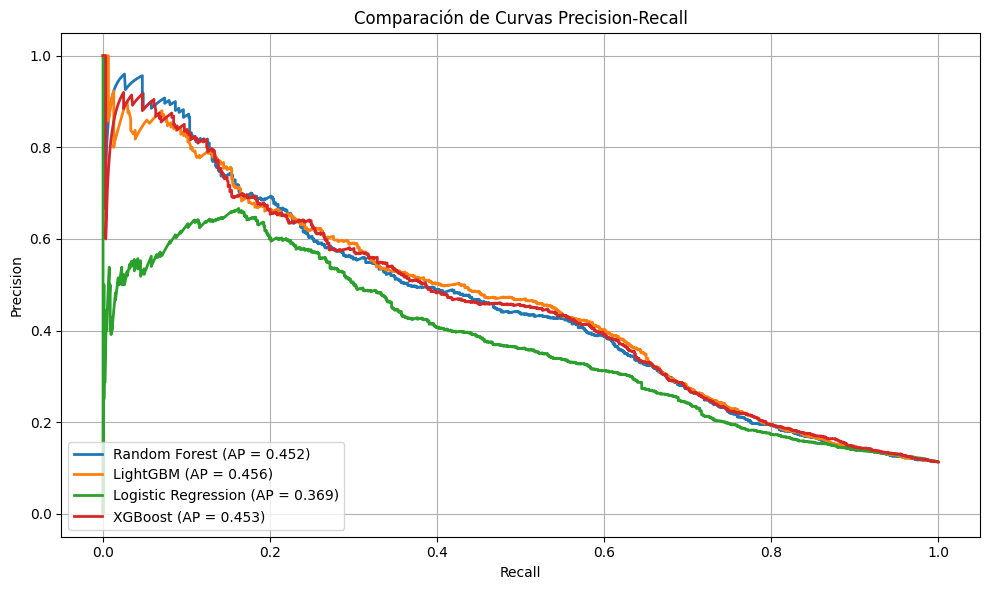

In [45]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precision_rf, recall_rf, _ = precision_recall_curve(y_test, best_rf.predict_proba(X_test)[:, 1])
precision_lgb, recall_lgb, _ = precision_recall_curve(y_test, best_lgb.predict_proba(X_test)[:, 1])
precision_log, recall_log, _ = precision_recall_curve(y_test, best_logreg.predict_proba(X_test)[:, 1])
precision_xgb, recall_xgb, _ = precision_recall_curve(y_test, best_xgb.predict_proba(X_test)[:, 1])

ap_rf = average_precision_score(y_test, best_rf.predict_proba(X_test)[:, 1])
ap_lgb = average_precision_score(y_test, best_lgb.predict_proba(X_test)[:, 1])
ap_log = average_precision_score(y_test, best_logreg.predict_proba(X_test)[:, 1])
ap_xgb = average_precision_score(y_test, best_xgb.predict_proba(X_test)[:, 1])

plt.figure(figsize=(10, 6))
plt.plot(recall_rf, precision_rf, label=f'Random Forest (AP = {ap_rf:.3f})', linewidth=2)
plt.plot(recall_lgb, precision_lgb, label=f'LightGBM (AP = {ap_lgb:.3f})', linewidth=2)
plt.plot(recall_log, precision_log, label=f'Logistic Regression (AP = {ap_log:.3f})', linewidth=2)
plt.plot(recall_xgb, precision_xgb, label=f'XGBoost (AP = {ap_xgb:.3f})', linewidth=2)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Comparación de Curvas Precision-Recall')
plt.legend(loc='lower left')
plt.grid(True)
plt.tight_layout()
plt.show()

## Elección de modelo

Recomiendo utilizar el modelo **LightGBM** de acuerdo a los siguientes criterios observados en el escenario realista 

| Criterio                          | Resultado                                                         |
| --------------------------------- | ----------------------------------------------------------------- |
| **Recall**                        | 0.6171 — suficientemente alto, en el top 3 de modelos             |
| **Precision**                     | 0.3849 — la segunda más alta entre todos los modelos evaluados    |
| **F1-score**                      | 0.4741 — mejor equilibrio entre precisión y recall                |
| **ROC AUC**                       | 0.7914 — excelente capacidad global de discriminación             |
| **Velocidad / escalabilidad**     | Entrenamiento muy eficiente, ideal para entornos productivos      |
| **Simplicidad en interpretación** | Permite extraer e interpretar fácilmente importancia de variables |

**Conclusión:** LightGBM representa la mejor combinación entre recall competitivo y rendimiento global (AUC, F1, precision), manteniendo eficiencia computacional y facilidad de análisis. Es una opción robusta y lista para producción.

,Feature,Importancia
4,economic_index,900
0,campaign,353
7,education_ord,276
3,age_bin,262
1,nr.employed,242
5,job_group,152
11,contact_bin,144
6,marital_code,133
16,pout_failure,110
2,prev_contact,92


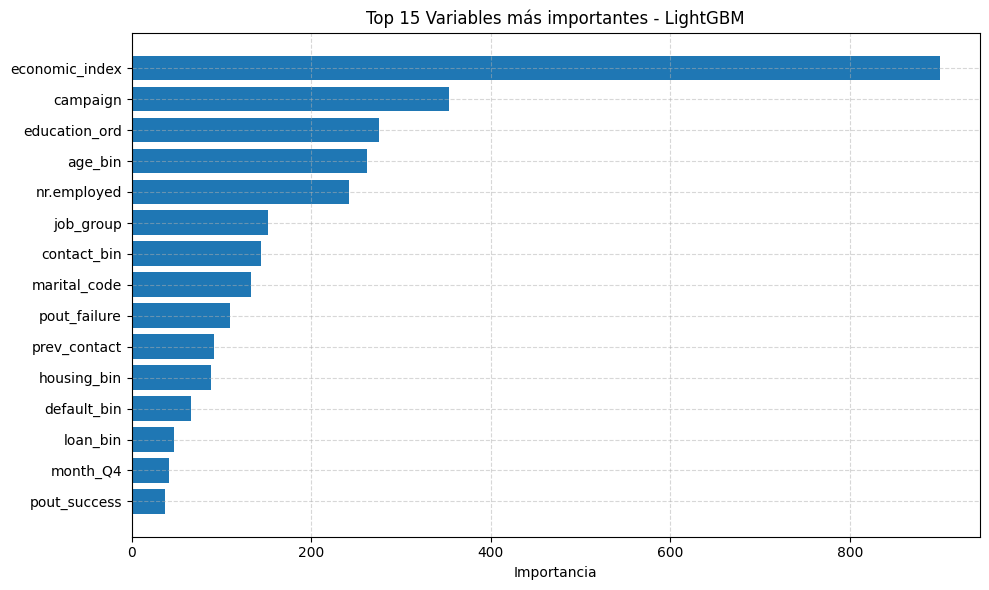

In [46]:
importancias = pd.DataFrame({
    'Feature': X_train.columns,
    'Importancia': best_lgb.feature_importances_
}).sort_values(by='Importancia', ascending=False)

display(importancias.head(10))

plt.figure(figsize=(10, 6))
plt.barh(importancias.head(15)['Feature'][::-1], importancias.head(15)['Importancia'][::-1])
plt.xlabel("Importancia")
plt.title("Top 15 Variables más importantes - LightGBM")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


## Guardar modelo

In [47]:
os.makedirs('models', exist_ok=True)

dump(best_lgb, '../models/lightgbm_model.joblib')

print("✅ Modelo guardado en: models/lightgbm_model.joblib")

with open('../models/lightgbm_model.pkl', 'wb') as f:
    pickle.dump(best_lgb, f)

print("✅ Modelos guardados correctamente.")

joblib_size = os.path.getsize('../models/lightgbm_model.joblib') / 1024
pkl_size = os.path.getsize('../models/lightgbm_model.pkl') / 1024

print(f"📦 Tamaño .joblib: {joblib_size:.2f} KB")
print(f"📦 Tamaño .pkl:    {pkl_size:.2f} KB")

✅ Modelo guardado en: models/lightgbm_model.joblib
✅ Modelos guardados correctamente.
📦 Tamaño .joblib: 340.05 KB
📦 Tamaño .pkl:    339.87 KB
